# Task 1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from astropy.cosmology import FlatLambdaCDM

plt.rcParams['figure.dpi'] = 130
plt.rcParams['axes.grid'] = True

In [2]:
DATA_HD  = "DATA/DES-Dovekie_HD.csv"
DATA_COV = "DATA/STAT+SYS.npz"

def load_dovekie_hd(path):
    """
    Load DES-Dovekie HD file, handling 'VARNAMES:' and possible 'SN:' prefixes.
    """
    rows = []
    varnames = None
    with open(path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.startswith('#'):
                continue
            if line.startswith('VARNAMES:'):
                varnames = line.split(':', 1)[1].strip().split()
                continue
            if line.startswith('SN:'):
                parts = line.split()
                vals = parts[1:]  # drop "SN:"
            else:
                vals = line.split()

            if varnames is None:
                varnames = [f'col{i}' for i in range(len(vals))]

            if len(vals) != len(varnames):
                continue

            rows.append(vals)

    hd = pd.DataFrame(rows, columns=varnames)

    # Convert common numeric columns
    for c in ['IDSURVEY','zHD','zHEL','MU','MUERR','MUERR_VPEC','MUERR_SYS','PROBIA_BEAMS','ISDATA_REAL']:
        if c in hd.columns:
            hd[c] = pd.to_numeric(hd[c], errors='coerce')

    return hd

def second_derivative(f, x, h):
    """Finite-difference second derivative."""
    return (f(x+h) - 2*f(x) + f(x-h)) / (h*h)

In [3]:
hd = load_dovekie_hd(DATA_HD)
print('hd shape:', hd.shape)
print('columns:', hd.columns.tolist())

# Keep only real SNe used for cosmology
if "ISDATA_REAL" in hd.columns:
    hd = hd[hd["ISDATA_REAL"] == 1]

needed_cols = ["zHD", "zHEL", "MU", "MUERR"]
mask = (hd["zHD"] > 0) & (~hd[needed_cols].isna().any(axis=1))
hd = hd.loc[mask].copy()

z_cmb  = hd["zHD"].to_numpy()
z_hel  = hd["zHEL"].to_numpy()
mu_obs = hd["MU"].to_numpy()
mu_err = hd["MUERR"].to_numpy()

print("Using", len(mu_obs), "supernovae.")
print(hd[["zHD","zHEL","MU","MUERR"]].head())


hd shape: (1820, 9)
columns: ['CID', 'IDSURVEY', 'zHD', 'zHEL', 'MU', 'MUERR', 'MUERR_VPEC', 'MUERR_SYS', 'PROBIA_BEAMS']
Using 1820 supernovae.
       zHD     zHEL        MU   MUERR
0  0.02509  0.02507  35.25995  0.1773
1  0.02510  0.02528  35.08017  0.1641
2  0.02510  0.02604  34.98002  0.1331
3  0.02512  0.02403  35.13565  0.1211
4  0.02517  0.02428  35.21658  0.1559


In [4]:
from scipy.linalg import cholesky

# Rebuild the sample mask before applying it to the covariance.
needed_cols = ["zHD", "zHEL", "MU", "MUERR"]
hd_full = load_dovekie_hd(DATA_HD)
if "ISDATA_REAL" in hd_full.columns:
    hd_full = hd_full[hd_full["ISDATA_REAL"] == 1]
mask_full = (hd_full["zHD"] > 0) & (~hd_full[needed_cols].isna().any(axis=1))

d = np.load(DATA_COV)
n_tot = int(d["nsn"][0])
packed_inv_cov = d["cov"]
if len(packed_inv_cov) != n_tot * (n_tot + 1) // 2:
    raise ValueError("Packed inverse covariance size does not match nsn.")

inv_cov_full = np.zeros((n_tot, n_tot), dtype=float)
inv_cov_full[np.triu_indices(n_tot)] = packed_inv_cov
inv_cov_full[np.tril_indices(n_tot, -1)] = inv_cov_full.T[np.tril_indices(n_tot, -1)]
cov_full = np.linalg.inv(inv_cov_full)

if len(mask_full) != n_tot:
    raise ValueError(
        f"HD selection has {len(mask_full)} rows but covariance has {n_tot}; "
        "confirm the release ordering and sample selection."
    )

cov_masked = cov_full[mask_full.to_numpy()][:, mask_full.to_numpy()]
cov_sn = cov_masked
L_sn = cholesky(cov_sn, lower=True, check_finite=False)
P = np.linalg.inv(cov_masked)

print("Covariance shape (masked):", cov_masked.shape)
print("Precision shape:", P.shape)


Covariance shape (masked): (1820, 1820)
Precision shape: (1820, 1820)


In [5]:
H0_fixed = 70.0
c_light = 299792.458
fz = (1.0 + z_hel) / (1.0 + z_cmb)  # DES factor

def mu_model(Om0):
    cosmo = FlatLambdaCDM(H0=H0_fixed, Om0=Om0)
    dL = cosmo.luminosity_distance(z_cmb).value  # Mpc
    dL_eff = dL * fz
    return 5.0 * np.log10(dL_eff) + 25.0

# Precompute constant pieces for marginalization over a constant offset
ones = np.ones_like(mu_obs)
v = P @ ones
C = float(ones @ v)
s = P @ mu_obs
s1 = float(ones @ s)

def chi2_marginalized(Om0):
    mu_mod = mu_model(Om0)
    Pm = P @ mu_mod
    A = float(mu_mod @ Pm) - 2.0 * float(mu_mod @ s)
    B = float(ones @ Pm) - s1
    return A - (B*B)/C

res = minimize_scalar(chi2_marginalized, bounds=(0.1, 0.5), method="bounded")
Om0_best = float(res.x)
chi2_min = float(res.fun)

# 1σ via curvature (Δχ² ≈ 1)
h = 0.01
curv = second_derivative(chi2_marginalized, Om0_best, h)
if curv <= 0:
    h = 0.005
    curv = second_derivative(chi2_marginalized, Om0_best, h)

Om_err = float(np.sqrt(2.0 / curv))

print(f"Best-fit Ωm = {Om0_best:.6f} ± {Om_err:.6f}")


Best-fit Ωm = 0.330317 ± 0.015261


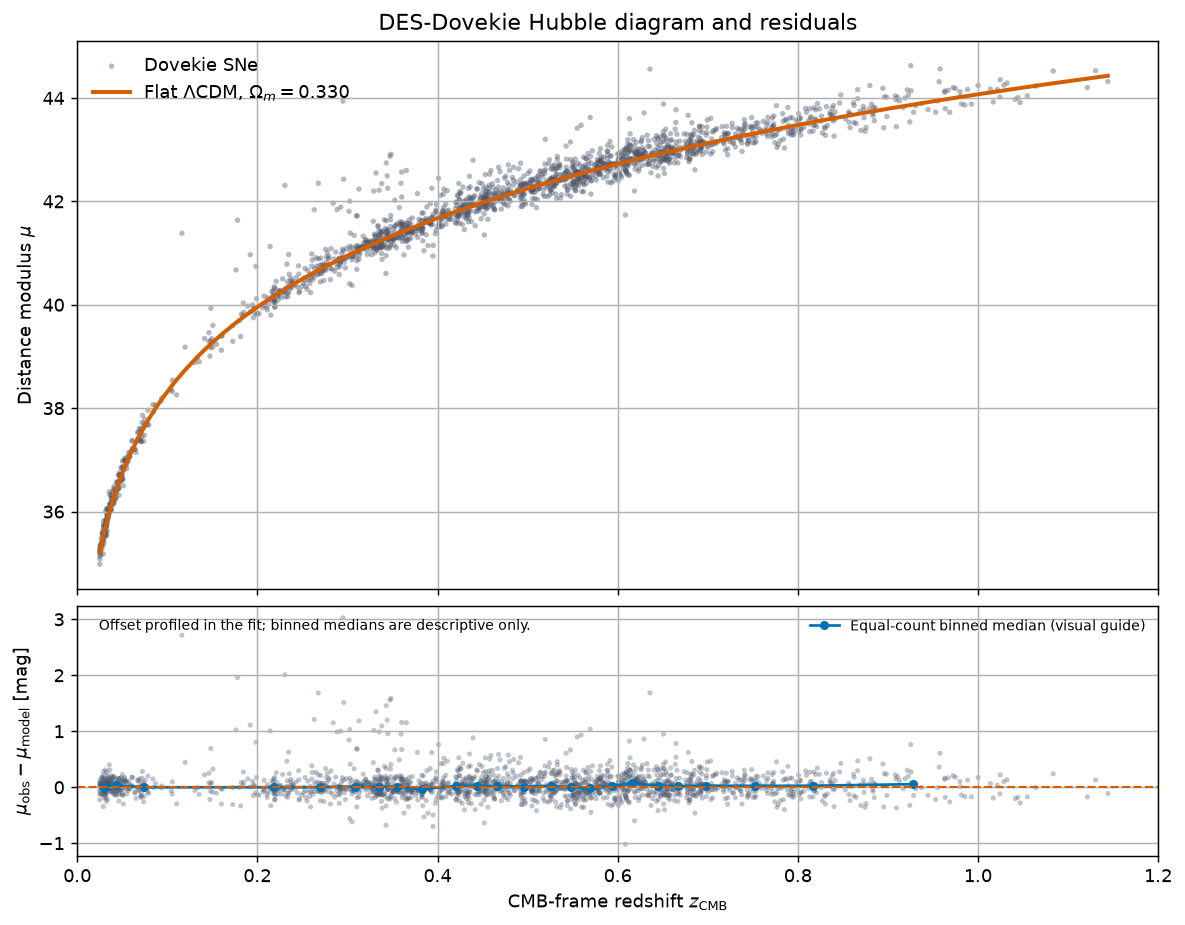

In [ ]:
# The likelihood profiles a common distance-modulus offset, so include it in the displayed model.
mu_best = mu_model(Om0_best)
residual_unshifted = mu_obs - mu_best
model_offset = float((np.ones_like(mu_obs) @ P @ residual_unshifted) / (np.ones_like(mu_obs) @ P @ np.ones_like(mu_obs)))
mu_fit = mu_best + model_offset
residual_mu = mu_obs - mu_fit
order = np.argsort(z_cmb)

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]}, constrained_layout=True)
axes[0].scatter(z_cmb, mu_obs, s=9, alpha=0.42, color="#4C566A", edgecolors="none", label="Dovekie SNe")
axes[0].plot(z_cmb[order], mu_fit[order], color="#D55E00", lw=2.2, label=fr"Flat $\Lambda$CDM, $\Omega_m={Om0_best:.3f}$")
axes[0].set_ylabel(r"Distance modulus $\mu$")
axes[0].set_title("DES-Dovekie Hubble diagram and residuals")
axes[0].legend(frameon=False, loc="upper left")

axes[1].scatter(z_cmb, residual_mu, s=8, alpha=0.35, color="#4C566A", edgecolors="none")
median_z, median_residual = [], []
for group in np.array_split(order, 24):
    median_z.append(float(np.median(z_cmb[group])))
    median_residual.append(float(np.median(residual_mu[group])))
axes[1].plot(median_z, median_residual, "o-", color="#0072B2", lw=1.5, ms=4, label="Equal-count binned median (visual guide)")
axes[1].axhline(0.0, color="#D55E00", lw=1.2, ls="--")
axes[1].set_xlabel(r"CMB-frame redshift $z_{\rm CMB}$")
axes[1].set_ylabel(r"$\mu_{\rm obs}-\mu_{\rm model}$ [mag]")
axes[1].set_xlim(0.0, 1.2)
axes[1].legend(frameon=False, loc="best", fontsize=8)
axes[1].text(0.02, 0.95, "Offset profiled in the fit; binned medians are descriptive only.", transform=axes[1].transAxes, va="top", fontsize=8)
plt.show()

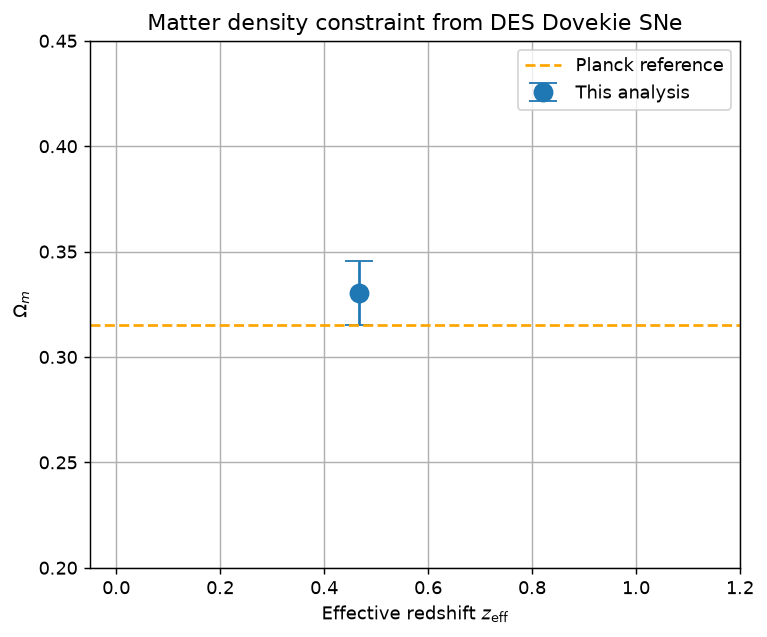

In [7]:
z_eff = float(np.mean(z_cmb))

plt.figure(figsize=(6,5))
plt.errorbar(z_eff, Om0_best, yerr=Om_err, fmt='o', ms=10, capsize=8, label="This analysis")
plt.axhline(0.315, ls='--', c='orange', label='Planck reference')
plt.xlim(-0.05, 1.2)
plt.ylim(0.2, 0.45)
plt.xlabel('Effective redshift $z_{\\rm eff}$')
plt.ylabel('$\\Omega_m$')
plt.title('Matter density constraint from DES Dovekie SNe')
plt.legend()
plt.tight_layout()
plt.show()


In [8]:
target_zeff = 0.295
tol = 5e-4

z_lo = float(np.min(z_cmb))
z_hi = float(np.max(z_cmb))

def weighted_zeff_for_cut(zmax):
    sel = (z_cmb <= zmax)
    if np.count_nonzero(sel) < 5:
        return np.inf
    w = 1.0 / (mu_err[sel]**2)  # supervisor's weighting
    return float(np.sum(z_cmb[sel] * w) / np.sum(w))

# Bisection on z_max
lo, hi = z_lo, z_hi
m = np.inf
for _ in range(80):
    mid = 0.5 * (lo + hi)
    m = weighted_zeff_for_cut(mid)

    if m == np.inf:
        hi = mid
        continue

    if m > target_zeff:
        hi = mid
    else:
        lo = mid

    if abs(m - target_zeff) < tol:
        break

z_max = 0.5 * (lo + hi)
keep = (z_cmb <= z_max)

w_keep = 1.0 / (mu_err[keep]**2)
z_eff_weighted = float(np.sum(z_cmb[keep] * w_keep) / np.sum(w_keep))
z_eff_unweighted = float(np.mean(z_cmb[keep]))

print(f"Chosen z_max = {z_max:.5f}")
print(f"Kept {keep.sum()} / {len(z_cmb)} SNe")
print(f"Weighted z_eff (used) = {z_eff_weighted:.6f}")
print(f"Unweighted z_eff      = {z_eff_unweighted:.6f}")


Chosen z_max = 0.59884
Kept 1264 / 1820 SNe
Weighted z_eff (used) = 0.294568
Unweighted z_eff      = 0.352710


In [9]:
# Trim arrays
z_cmb_trim  = z_cmb[keep]
z_hel_trim  = z_hel[keep]
mu_obs_trim = mu_obs[keep]
mu_err_trim = mu_err[keep]

# Trim covariance consistently
cov_trim = cov_masked[keep][:, keep]
P_trim = np.linalg.inv(cov_trim)

# Model pieces
fz_trim = (1.0 + z_hel_trim) / (1.0 + z_cmb_trim)

def mu_model_trim(Om0):
    cosmo = FlatLambdaCDM(H0=H0_fixed, Om0=Om0)
    dL = cosmo.luminosity_distance(z_cmb_trim).value
    dL_eff = dL * fz_trim
    return 5.0 * np.log10(dL_eff) + 25.0

# Precompute marginalization constants
ones_t = np.ones_like(mu_obs_trim)
vt = P_trim @ ones_t
Ct = float(ones_t @ vt)
st = P_trim @ mu_obs_trim
s1t = float(ones_t @ st)

def chi2_marginalized_trim(Om0):
    mu_mod = mu_model_trim(Om0)
    Pm = P_trim @ mu_mod
    A = float(mu_mod @ Pm) - 2.0 * float(mu_mod @ st)
    B = float(ones_t @ Pm) - s1t
    return A - (B*B)/Ct

# Fit Ωm
res = minimize_scalar(chi2_marginalized_trim, bounds=(0.10, 0.50), method="bounded")
Om0_best_trim = float(res.x)
chi2_min_trim = float(res.fun)

# Curvature-based uncertainty
h = 0.01
curv = second_derivative(chi2_marginalized_trim, Om0_best_trim, h)
if curv <= 0:
    h = 0.005
    curv = second_derivative(chi2_marginalized_trim, Om0_best_trim, h)

Om_err_trim = float(np.sqrt(2.0 / curv))

print("\n================ Trimmed DES–Dovekie SN-only Result ================")
print(f"Target weighted z_eff:        {target_zeff:.6f}")
print(f"Achieved weighted z_eff:      {z_eff_weighted:.6f}")
print(f"Best-fit Ωm (flat ΛCDM):      {Om0_best_trim:.6f}")
print(f"1σ uncertainty (curvature):   {Om_err_trim:.6f}")
print(f"Final report:                 Ωm = {Om0_best_trim:.3f} ± {Om_err_trim:.3f}")
print("====================================================================\n")



================ Trimmed DES–Dovekie SN-only Result ================
Target weighted z_eff:        0.295000
Achieved weighted z_eff:      0.294568
Best-fit Ωm (flat ΛCDM):      0.350633
1σ uncertainty (curvature):   0.021263
Final report:                 Ωm = 0.351 ± 0.021



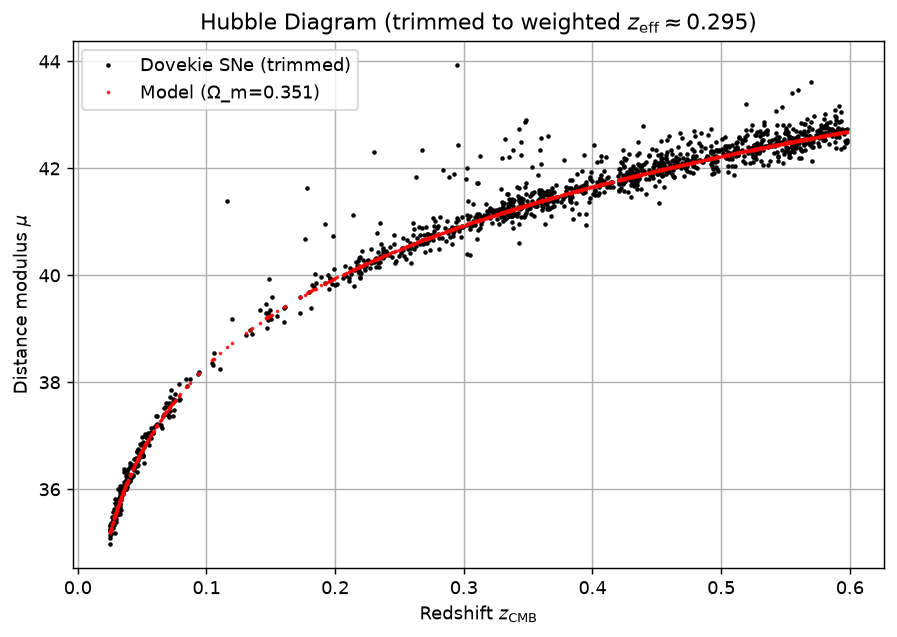

In [10]:
mu_best_trim = mu_model_trim(Om0_best_trim)

plt.figure(figsize=(7,5))
plt.plot(z_cmb_trim, mu_obs_trim, 'k.', ms=3, label='Dovekie SNe (trimmed)')
plt.plot(z_cmb_trim, mu_best_trim, 'r.', ms=2, alpha=0.8,
         label=f'Model (Ω_m={Om0_best_trim:.3f})')
plt.xlabel('Redshift $z_{\\rm CMB}$')
plt.ylabel('Distance modulus $\\mu$')
plt.title(f'Hubble Diagram (trimmed to weighted $z_{{\\rm eff}}\\approx{target_zeff:.3f}$)')
plt.legend()
plt.tight_layout()
plt.show()


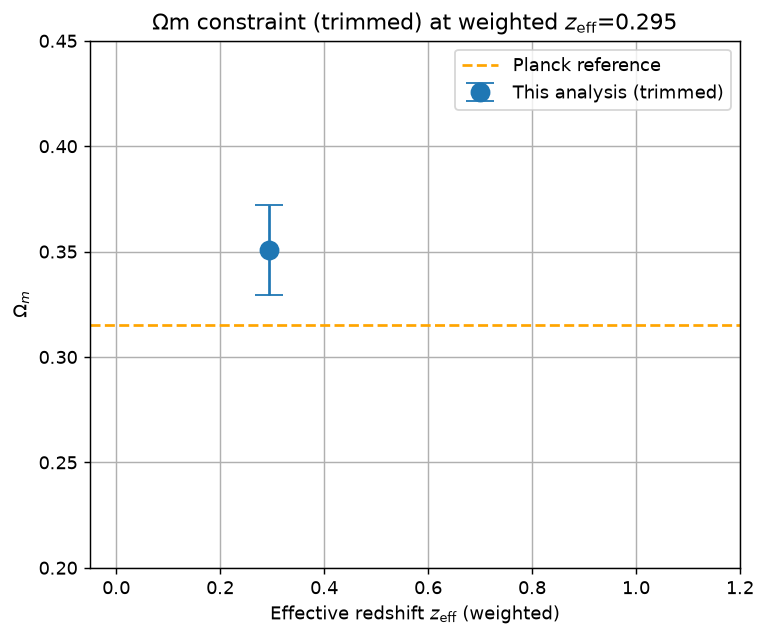

In [11]:
plt.figure(figsize=(6,5))
plt.errorbar(z_eff_weighted, Om0_best_trim, yerr=Om_err_trim, fmt='o',
             ms=10, capsize=8, label="This analysis (trimmed)")
plt.axhline(0.315, ls='--', c='orange', label='Planck reference')
plt.xlim(-0.05, 1.2)
plt.ylim(0.2, 0.45)
plt.xlabel('Effective redshift $z_{\\rm eff}$ (weighted)')
plt.ylabel('$\\Omega_m$')
plt.title(f'Ωm constraint (trimmed) at weighted $z_{{\\rm eff}}$={z_eff_weighted:.3f}')
plt.legend()
plt.tight_layout()
plt.show()


# Task 2

In [12]:
%pip install emcee


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
from scipy.integrate import cumulative_trapezoid

df_full = load_dovekie_hd(DATA_HD)

if "ISDATA_REAL" in df_full.columns:
    df_full = df_full[df_full["ISDATA_REAL"] == 1]

needed_cols = ["zHD", "zHEL", "MU", "MUERR"]
mask_full = (df_full["zHD"] > 0) & (~df_full[needed_cols].isna().any(axis=1))
df = df_full.loc[mask_full].copy()

print("Task 2 cleaned shape:", df.shape)
if "IDSURVEY" in df.columns:
    print("Survey breakdown:")
    print(df["IDSURVEY"].value_counts().sort_index())

zHD_all   = df["zHD"].to_numpy()
zHEL_all  = df["zHEL"].to_numpy()
mu_all    = df["MU"].to_numpy()

d = np.load(DATA_COV)

n_tot = int(d[d.files[0]][0])

inv_cov_full = np.zeros((n_tot, n_tot))
inv_cov_full[np.triu_indices(n_tot)] = d[d.files[1]]
inv_cov_full[np.tril_indices(n_tot, -1)] = inv_cov_full.T[np.tril_indices(n_tot, -1)]

cov_full = np.linalg.inv(inv_cov_full)

cov_masked = cov_full[mask_full.values][:, mask_full.values]

print("Covariance shape (masked to cleaned SN set):", cov_masked.shape)


Task 2 cleaned shape: (1820, 9)
Survey breakdown:
IDSURVEY
5         8
10     1623
63       16
64       31
65       22
66        3
150     117
Name: count, dtype: int64


Covariance shape (masked to cleaned SN set): (1820, 1820)


In [14]:
def mu_theory(zHD, zHEL, Om, H0, ngrid=2000):
    zHD  = np.asarray(zHD)
    zHEL = np.asarray(zHEL)

    zmax = float(zHD.max())
    zg = np.linspace(0.0, zmax, ngrid)

    Ez = np.sqrt(Om * (1.0 + zg)**3 + (1.0 - Om))
    chi = cumulative_trapezoid(1.0 / Ez, zg, initial=0.0)

    chi_z = np.interp(zHD, zg, chi)

    dL = (1.0 + zHEL) * (c_light / H0) * chi_z
    return 5.0 * np.log10(dL) + 25.0


def chi2_profiled_M(mu_obs, mu_th, cov, ones, Pones, oPo):
    r = mu_obs - mu_th
    Pr   = np.linalg.solve(cov, r)
    rPr  = float(r @ Pr)
    oPr  = float(ones @ Pr)
    return rPr - (oPr * oPr) / oPo


def profile_likelihood_Om_fullcov(zHD, zHEL, mu, cov, Om_grid, H0):

    N = len(mu)
    ones = np.ones(N)

    Pones = np.linalg.solve(cov, ones)
    oPo   = float(ones @ Pones)

    chi2_vals = np.empty(len(Om_grid))

    for i, Om in enumerate(Om_grid):
        mu_th = mu_theory(zHD, zHEL, Om, H0)
        chi2_vals[i] = chi2_profiled_M(
            mu, mu_th, cov, ones, Pones, oPo
        )

    chi2_min = float(np.min(chi2_vals))
    R = np.exp(-0.5 * (chi2_vals - chi2_min))
    R /= np.max(R)

    return chi2_vals, R


def intervals_from_chi2(Om_grid, chi2_vals):
    chi2_min = float(np.min(chi2_vals))
    dchi2 = chi2_vals - chi2_min

    # Wilks: Δχ² <= 1
    m = (dchi2 <= 1.0)
    if np.any(m):
        lo_w, hi_w = Om_grid[m][0], Om_grid[m][-1]
    else:
        lo_w, hi_w = np.nan, np.nan

    # Integrated 68% region using R ∝ exp(-Δχ²/2)
    R = np.exp(-0.5 * dchi2)
    area = np.trapezoid(R, Om_grid)
    if area <= 0:
        lo_i, hi_i = np.nan, np.nan
    else:
        target = 0.68 * area
        # find threshold t such that integral of R where R>=t equals target
        lo, hi = 0.0, float(np.max(R))
        for _ in range(60):
            mid = 0.5 * (lo + hi)
            area_mid = np.trapezoid(np.where(R >= mid, R, 0.0), Om_grid)
            if area_mid >= target:
                lo = mid
            else:
                hi = mid
        keep = (R >= lo)
        idx = np.where(keep)[0]
        lo_i, hi_i = Om_grid[idx[0]], Om_grid[idx[-1]]

    return (lo_w, hi_w), (lo_i, hi_i)


In [15]:

# Redshift cuts and plot colors (Fig. 2 of the paper)
Z_CUTS = {
    0.05: "cyan",
    0.5:  "black",
    0.6:  "blue",
    0.7:  "green",
    0.8:  "red",
}

OM_GRID = np.linspace(0.05, 3.0, 2000)

z > 0.05: N = 1679
z > 0.5: N = 862
z > 0.6: N = 552
z > 0.7: N = 257
z > 0.8: N = 130


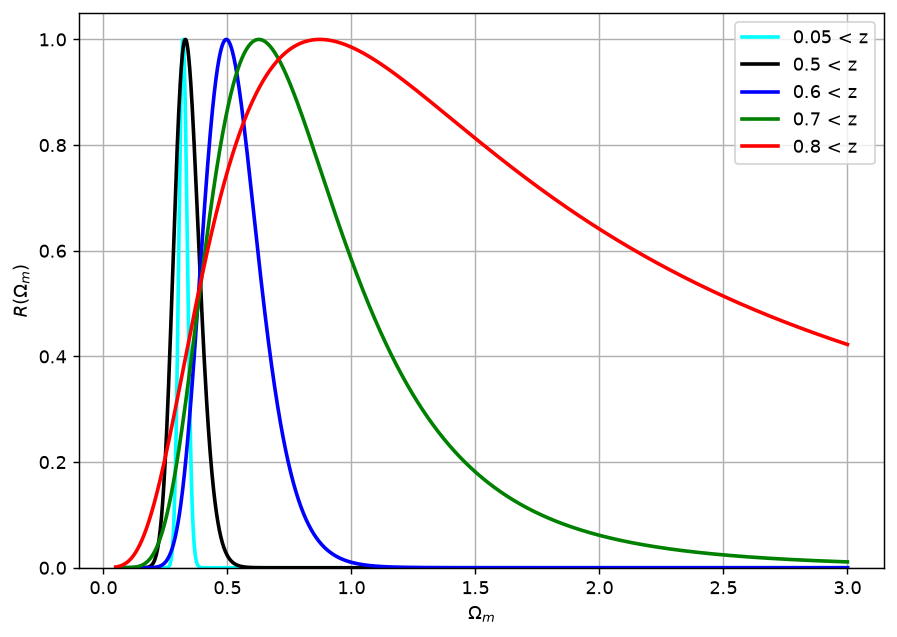


Redshift    #SNe    Om_best   Om(68%)_int                 Om(Δχ²<=1)
 0.05<z    1679   0.3215   0.3215+ 0.0162- 0.0177   0.3215+ 0.0162- 0.0162
 0.50<z     862   0.3304   0.3304+ 0.0546- 0.0472   0.3304+ 0.0531- 0.0472
 0.60<z     552   0.4957   0.4957+ 0.1299- 0.1018   0.4957+ 0.1240- 0.0989
 0.70<z     257   0.6270   0.6270+ 0.4412- 0.2435   0.6270+ 0.3542- 0.2140
 0.80<z     130   0.8720   0.8720+ 1.1186- 0.4309   0.8720+ 1.2485- 0.4486


In [16]:
plt.figure(figsize=(7, 5))

results_table = []  # store summary for printing

for zmin, color in Z_CUTS.items():
    sel = (zHD_all > zmin)
    N = int(np.sum(sel))
    print(f"z > {zmin}: N = {N}")

    zHD  = zHD_all[sel]
    zHEL = zHEL_all[sel]
    mu   = mu_all[sel]
    cov  = cov_masked[sel][:, sel]

    chi2_vals, R = profile_likelihood_Om_fullcov(zHD, zHEL, mu, cov, OM_GRID, H0_fixed)

    # best-fit + intervals
    i0 = int(np.argmin(chi2_vals))
    Om_best = float(OM_GRID[i0])

    (lo_w, hi_w), (lo_i, hi_i) = intervals_from_chi2(OM_GRID, chi2_vals)

    results_table.append((zmin, N, Om_best, lo_i, hi_i, lo_w, hi_w))

    plt.plot(OM_GRID, R, color=color, lw=2, label=f"{zmin} < z")

plt.xlabel(r"$\Omega_m$")
plt.ylabel(r"$R(\Omega_m)$")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

# ---- Print table analogous to Table I output ----
print("\nRedshift    #SNe    Om_best   Om(68%)_int                 Om(Δχ²<=1)")
for (zmin, N, Om_best, lo_i, hi_i, lo_w, hi_w) in results_table:
    print(f"{zmin:>5.2f}<z  {N:>6d}   {Om_best:6.4f}   "
          f"{Om_best:6.4f}+{hi_i-Om_best:7.4f}-{Om_best-lo_i:7.4f}   "
          f"{Om_best:6.4f}+{hi_w-Om_best:7.4f}-{Om_best-lo_w:7.4f}")


In [17]:
%pip install tqdm

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [18]:

import emcee
from scipy.stats import gaussian_kde
from scipy.linalg import cholesky, solve_triangular
from scipy.integrate import cumulative_trapezoid

In [19]:
def mu_theory_fast(zHD, zHEL, Om, H0, zg=None):
    """
    Flat ΛCDM distance modulus (fast, vectorised):
      - integral uses zHD
      - prefactor uses (1 + zHEL)
    If zg is provided, reuse that z-grid for speed.
    """
    zHD  = np.asarray(zHD)
    zHEL = np.asarray(zHEL)

    if zg is None:
        zmax = float(np.max(zHD))
        zg = np.linspace(0.0, zmax, 2000)

    Ez = np.sqrt(Om * (1.0 + zg)**3 + (1.0 - Om))
    chi = cumulative_trapezoid(1.0 / Ez, zg, initial=0.0)
    chi_z = np.interp(zHD, zg, chi)

    dL = (1.0 + zHEL) * (c_light / H0) * chi_z  # Mpc
    return 5.0 * np.log10(dL) + 25.0


In [20]:

def make_loglike_profiled_offset(zHD, zHEL, mu, cov, H0_fixed):
    """
    Returns a function loglike(Om) that:
      - uses full covariance cov
      - profiles over constant offset M
      - uses Cholesky for speed
      - uses correct (zHD, zHEL) prescription
    """

    # Cholesky: cov = L L^T  (lower-triangular)
    L = cholesky(cov, lower=True, check_finite=False)

    N = len(mu)
    ones = np.ones(N)

    # Precompute y_ones = L^{-1} ones  and oPo = ones^T C^{-1} ones = ||y_ones||^2
    y_ones = solve_triangular(L, ones, lower=True, check_finite=False)
    oPo = float(y_ones @ y_ones)

    # Reuse a z-grid for this cut to speed mu_theory_fast
    zmax = float(np.max(zHD))
    zg = np.linspace(0.0, zmax, 2000)

    def loglike(Om):
        # prior domain check here (fast reject)
        if not (0.01 < Om < 3.0):
            return -np.inf

        mu_th = mu_theory_fast(zHD, zHEL, Om, H0_fixed, zg=zg)
        r = mu - mu_th

        # y_r = L^{-1} r
        y_r = solve_triangular(L, r, lower=True, check_finite=False)

        # r^T C^{-1} r = ||y_r||^2
        rPr = float(y_r @ y_r)

        # ones^T C^{-1} r = (L^{-1} ones)·(L^{-1} r)
        oPr = float(y_ones @ y_r)

        chi2_prof = rPr - (oPr * oPr) / oPo
        return -0.5 * chi2_prof

    return loglike


def run_mcmc_Om(loglike, nwalkers=40, nsteps=4000, burn=1000, thin=5):
    """
    Ωm-only MCMC. Returns flat samples of shape (Nsamples,).
    """
    ndim = 1
    rng = np.random.default_rng(123)

    # initialise walkers near a sensible region
    p0 = 0.30 + 1e-2 * rng.standard_normal((nwalkers, ndim))

    def logpost(theta):
        Om = float(theta[0])
        return loglike(Om)  # prior handled inside loglike

    sampler = emcee.EnsembleSampler(nwalkers, ndim, logpost)
    sampler.run_mcmc(p0, nsteps, progress=True)

    chain = sampler.get_chain(discard=burn, thin=thin, flat=True)
    samples = chain[:, 0]
    return samples, sampler



In [21]:
Z_CUTS_MCMC = [0.5, 0.6, 0.7, 0.8]
colors = {0.5:"black", 0.6:"blue", 0.7:"green", 0.8:"red"}

samples_by_z = {}
samplers_by_z = {}

for zmin in Z_CUTS_MCMC:
    sel = (zHD_all > zmin)

    zHD_cut  = zHD_all[sel]
    zHEL_cut = zHEL_all[sel]
    mu_cut   = mu_all[sel]
    cov_cut  = cov_masked[sel][:, sel]

    print(f"\nRunning Ωm-only MCMC for z > {zmin} (N={sel.sum()})")

    loglike = make_loglike_profiled_offset(zHD_cut, zHEL_cut, mu_cut, cov_cut, H0_fixed)

    samples, sampler = run_mcmc_Om(loglike)
    print("Mean acceptance:", np.mean(sampler.acceptance_fraction))

    samples_by_z[zmin] = samples
    samplers_by_z[zmin] = sampler



Running Ωm-only MCMC for z > 0.5 (N=862)


100%|██████████| 4000/4000 [00:49<00:00, 80.27it/s]


Mean acceptance: 0.8067249999999999

Running Ωm-only MCMC for z > 0.6 (N=552)


100%|██████████| 4000/4000 [00:34<00:00, 116.94it/s]


Mean acceptance: 0.8056437500000001

Running Ωm-only MCMC for z > 0.7 (N=257)


100%|██████████| 4000/4000 [00:23<00:00, 171.80it/s]


Mean acceptance: 0.78760625

Running Ωm-only MCMC for z > 0.8 (N=130)


100%|██████████| 4000/4000 [00:19<00:00, 200.90it/s]

Mean acceptance: 0.81111875


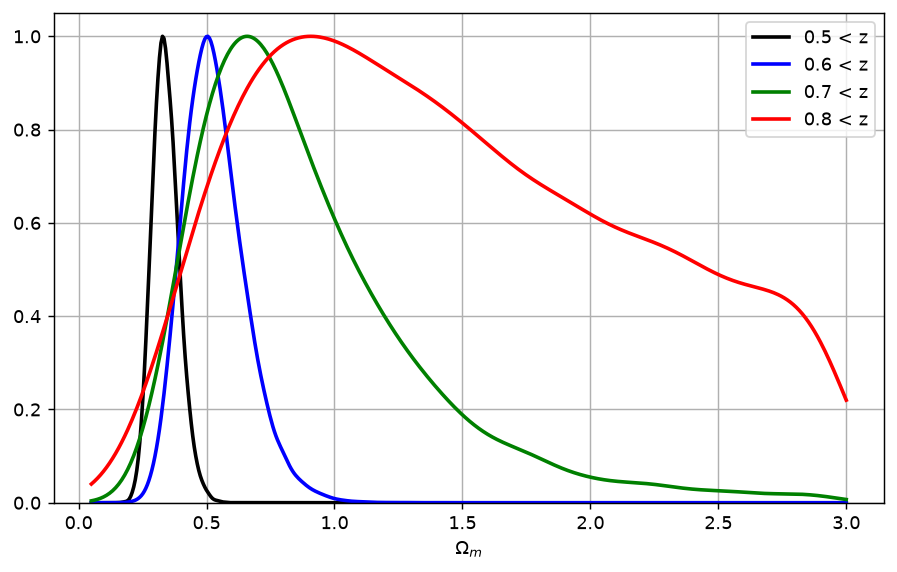

In [22]:
def kde_peak(x, grid, bw_factor=1.35):
    x = np.asarray(x)
    x = x[np.isfinite(x)]
    kde = gaussian_kde(x)
    kde.set_bandwidth(kde.factor * bw_factor)
    y = kde(grid)
    m = np.max(y)
    return y/m if m > 0 else y

Om_grid = np.linspace(0.05, 3.0, 500)

plt.figure(figsize=(7, 4.5))
for zmin in Z_CUTS_MCMC:
    s = samples_by_z[zmin]
    plt.plot(Om_grid, kde_peak(s, Om_grid, bw_factor=1.4), color=colors[zmin], lw=2, label=f"{zmin} < z")

plt.xlabel(r"$\Omega_m$")
plt.ylabel("")  # paper-style
plt.ylim(0.0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

The marginal H0​ posterior and the joint (H0,Ωm) panel are not shown because our supernova‑only analysis explicitly profiles out the absolute magnitude (or constant offset) using the full correlated likelihood. Once this nuisance parameter is treated correctly, the likelihood becomes independent of H0​, reflecting the well‑known fact that uncalibrated Type Ia supernovae constrain only the shape of the distance–redshift relation and not its absolute scale. As a result, the MCMC chains are one‑dimensional in Ωm​, and no statistically meaningful H0​ marginal or H0​–Ωm​ joint distribution can be constructed from these samples. Figures in the literature that display such panels rely on MCMC setups that retain the offset as a free parameter and are therefore intended for visualisation rather than representing identifiable supernova‑only constraints.

# Task 3

In [23]:
from scipy.optimize import minimize

BAO_MEAN  = "DATA/BAO/desi_gaussian_bao_ALL_GCcomb_mean.txt"
BAO_COV   = "DATA/BAO/desi_gaussian_bao_ALL_GCcomb_cov.txt"

c_light  = 299792.458
H0_truth = 67.4
Om_truth = 0.315

rs_fid = 1.0

ADD_NOISE = True
SEED_SN   = 123
SEED_BAO  = 456

def load_cov_matrix_any(path):
    vals = []
    with open(path, "r") as f:
        for line in f:
            s = line.strip()
            if not s or s.startswith("#"):
                continue
            for tok in s.replace(",", " ").split():
                try:
                    vals.append(float(tok))
                except ValueError:
                    pass
    vals = np.array(vals, dtype=float)
    N = int(np.sqrt(vals.size))
    if N*N != vals.size:
        raise ValueError(f"Cannot reshape covariance: read {vals.size} numbers (not a perfect square).")
    return vals.reshape(N, N)

def load_bao_mean_vector_any(path, N_required):
    tokens = ("DM_over_rs","DH_over_rs","DV_over_rs","DM_over_rd","DH_over_rd","DV_over_rd")
    z_list, obs_list, y_list = [], [], []

    with open(path, "r") as f:
        for line in f:
            s = line.strip()
            if not s or s.startswith("#"):
                continue
            parts = s.split()

            # observable token if present
            obs = None
            for p in parts:
                if any(t in p for t in tokens):
                    obs = p
                    break

            # numeric tokens
            nums = []
            for p in parts:
                try:
                    nums.append(float(p))
                except ValueError:
                    continue

            if len(nums) < 2:
                continue

            z = nums[0]
            y = nums[-1]
            if obs is None:
                obs = "DV_over_rs"

            z_list.append(z)
            obs_list.append(obs)
            y_list.append(y)

            if len(y_list) >= N_required:
                break

    if len(y_list) < N_required:
        raise ValueError(f"BAO mean vector extracted only {len(y_list)} rows, but covariance requires {N_required}.")
    return np.array(z_list[:N_required], float), np.array(obs_list[:N_required], object), np.array(y_list[:N_required], float)

cov_bao = load_cov_matrix_any(BAO_COV)
if cov_bao.shape[0] != cov_bao.shape[1]:
    raise ValueError(f"BAO covariance not square: {cov_bao.shape}")
N_bao = cov_bao.shape[0]

z_bao_vec, obs_bao_vec, y_bao_obs = load_bao_mean_vector_any(BAO_MEAN, N_bao)
L_bao = cholesky(cov_bao, lower=True, check_finite=False)

print(f"BAO loaded: N={N_bao}; cov shape={cov_bao.shape}")
print("First 8 BAO rows:", list(zip(z_bao_vec[:8], obs_bao_vec[:8], y_bao_obs[:8])))

BAO loaded: N=13; cov shape=(13, 13)
First 8 BAO rows: [(np.float64(0.295), 'DV_over_rs', np.float64(7.94167639)), (np.float64(0.51), 'DM_over_rs', np.float64(13.58758434)), (np.float64(0.51), 'DH_over_rs', np.float64(21.86294686)), (np.float64(0.706), 'DM_over_rs', np.float64(17.35069094)), (np.float64(0.706), 'DH_over_rs', np.float64(19.45534918)), (np.float64(0.934), 'DM_over_rs', np.float64(21.57563956)), (np.float64(0.934), 'DH_over_rs', np.float64(17.64149464)), (np.float64(1.321), 'DM_over_rs', np.float64(27.60085612))]


In [24]:
def E_lcdm(z, Om):
    return np.sqrt(Om*(1.0+z)**3 + (1.0-Om))

def chi_lcdm(z, Om, ngrid=4000):
    z = np.asarray(z)
    zg = np.linspace(0.0, float(np.max(z)), ngrid)
    Ez = E_lcdm(zg, Om)
    chi = cumulative_trapezoid(1.0/Ez, zg, initial=0.0)
    return np.interp(z, zg, chi)

def mu_lcdm(zHD, zHEL, H0, Om):
    chi = chi_lcdm(zHD, Om)
    dL = (1.0 + zHEL) * (c_light / H0) * chi
    return 5.0*np.log10(dL) + 25.0

def bao_theory_lcdm_vector(z_vec, obs_vec, H0, Om):
    z_vec = np.asarray(z_vec)
    chi = chi_lcdm(z_vec, Om)
    DM = (c_light / H0) * chi
    DH = c_light / (H0 * E_lcdm(z_vec, Om))
    DV = (z_vec * (DM**2) * DH) ** (1.0/3.0)

    out = np.empty_like(z_vec, dtype=float)
    for i, obs in enumerate(obs_vec):
        o = str(obs)
        if "DM_over" in o:
            out[i] = DM[i] / rs_fid
        elif "DH_over" in o:
            out[i] = DH[i] / rs_fid
        elif "DV_over" in o:
            out[i] = DV[i] / rs_fid
        else:
            out[i] = DV[i] / rs_fid
    return out

def H_cosmo(z, H0, q0, j0):
    return H0 * (1.0 + (1.0 + q0)*z + 0.5*(j0 - q0*q0)*z*z)

def chi_cosmo(z, H0, q0, j0, ngrid=4000):
    z = np.asarray(z)
    zmax = float(np.max(z))
    zg = np.linspace(0.0, zmax, ngrid)
    Hzg = H_cosmo(zg, H0, q0, j0)
    if np.any(Hzg <= 0):
        return None
    chi = cumulative_trapezoid(1.0/Hzg, zg, initial=0.0)
    return np.interp(z, zg, chi)

def mu_cosmo(zHD, zHEL, H0, q0, j0):
    chi = chi_cosmo(zHD, H0, q0, j0)
    if chi is None:
        return None
    dL = (1.0 + zHEL) * c_light * chi
    return 5.0*np.log10(dL) + 25.0

def bao_theory_cosmo_vector(z_vec, obs_vec, H0, q0, j0):
    z_vec = np.asarray(z_vec)
    chi = chi_cosmo(z_vec, H0, q0, j0)
    if chi is None:
        return None
    Hz = H_cosmo(z_vec, H0, q0, j0)
    if np.any(Hz <= 0):
        return None

    DM = c_light * chi
    DH = c_light / Hz
    DV = (z_vec * (DM**2) * DH) ** (1.0/3.0)

    out = np.empty_like(z_vec, dtype=float)
    for i, obs in enumerate(obs_vec):
        o = str(obs)
        if "DM_over" in o:
            out[i] = DM[i] / rs_fid
        elif "DH_over" in o:
            out[i] = DH[i] / rs_fid
        elif "DV_over" in o:
            out[i] = DV[i] / rs_fid
        else:
            out[i] = DV[i] / rs_fid
    return out

In [25]:
rng_sn  = np.random.default_rng(SEED_SN)
rng_bao = np.random.default_rng(SEED_BAO)

mu_sn_truth = mu_lcdm(zHD_all, zHEL_all, H0_truth, Om_truth)
y_bao_truth = bao_theory_lcdm_vector(z_bao_vec, obs_bao_vec, H0_truth, Om_truth)

if ADD_NOISE:
    mu_sn_mock = mu_sn_truth + (L_sn @ rng_sn.standard_normal(len(mu_sn_truth)))
    y_bao_mock = y_bao_truth + (L_bao @ rng_bao.standard_normal(len(y_bao_truth)))
else:
    mu_sn_mock = mu_sn_truth.copy()
    y_bao_mock = y_bao_truth.copy()

In [26]:
def chi2_from_cholesky(L, r):
    y = solve_triangular(L, r, lower=True, check_finite=False)
    return float(y @ y)

def chi2_joint(mu_model, y_bao_model):
    return chi2_from_cholesky(L_sn, (mu_sn_mock - mu_model)) + chi2_from_cholesky(L_bao, (y_bao_mock - y_bao_model))

In [27]:
def chi2_lcdm_params(p):
    H0, Om = p
    if not (40.0 < H0 < 90.0): return 1e99
    if not (0.01 < Om < 3.0):  return 1e99
    mu_m = mu_lcdm(zHD_all, zHEL_all, H0, Om)
    y_m  = bao_theory_lcdm_vector(z_bao_vec, obs_bao_vec, H0, Om)
    return chi2_joint(mu_m, y_m)

res_lcdm = minimize(
    chi2_lcdm_params,
    x0=np.array([67.0, 0.30]),
    method="Powell",
    options={"maxiter": 500, "xtol": 1e-6, "ftol": 1e-6, "disp": False}
)
print("LCDM success:", res_lcdm.success, res_lcdm.message, "nit=", res_lcdm.nit, "fun=", res_lcdm.fun)
print("LCDM x (full):", res_lcdm.x)
H0_fit_lcdm, Om_fit_lcdm = res_lcdm.x

def chi2_cosmo_params(p):
    H0, q0, j0 = p
    if not (40.0 < H0 < 90.0):  return 1e99
    if not (-5.0 < q0 < 5.0):   return 1e99
    if not (-50.0 < j0 < 50.0): return 1e99
    mu_m = mu_cosmo(zHD_all, zHEL_all, H0, q0, j0)
    if mu_m is None: return 1e99
    y_m = bao_theory_cosmo_vector(z_bao_vec, obs_bao_vec, H0, q0, j0)
    if y_m is None: return 1e99
    return chi2_joint(mu_m, y_m)

res_cosmo = minimize(
    chi2_cosmo_params,
    x0=np.array([67.0, -0.55, 1.0]),
    method="Powell",
    options={"maxiter": 800, "xtol": 1e-6, "ftol": 1e-6, "disp": False}
)
print("COSMO success:", res_cosmo.success, res_cosmo.message, "nit=", res_cosmo.nit, "fun=", res_cosmo.fun)
print("COSMO x (full):", res_cosmo.x)
H0_fit_cosmo, q0_fit_cosmo, j0_fit_cosmo = res_cosmo.x

LCDM success: True Optimization terminated successfully. nit= 5 fun= 1934.094142609245
LCDM x (full): [67.40136385  0.31499025]
COSMO success: True Optimization terminated successfully. nit= 10 fun= 14916.000730352966
COSMO x (full): [66.07798082 -0.39254151  0.58615081]


In [28]:
def fit_lcdm_subset(sel_sn, sel_bao):
    zHD = zHD_all[sel_sn]; zHEL = zHEL_all[sel_sn]
    muD = mu_sn_mock[sel_sn]
    covS = cov_sn[sel_sn][:, sel_sn]
    Ls = cholesky(covS, lower=True, check_finite=False)

    zb  = z_bao_vec[sel_bao]
    ob  = obs_bao_vec[sel_bao]
    yD  = y_bao_mock[sel_bao]
    covB = cov_bao[sel_bao][:, sel_bao]
    Lb = cholesky(covB, lower=True, check_finite=False)

    def chi2_local(p):
        H0, Om = p
        if not (40.0 < H0 < 90.0): return 1e99
        if not (0.01 < Om < 3.0):  return 1e99
        mu_m = mu_lcdm(zHD, zHEL, H0, Om)
        y_m  = bao_theory_lcdm_vector(zb, ob, H0, Om)
        y = solve_triangular(Ls, (muD-mu_m), lower=True, check_finite=False); chiS = float(y@y)
        y = solve_triangular(Lb, (yD-y_m), lower=True, check_finite=False); chiB = float(y@y)
        return chiS + chiB

    r = minimize(chi2_local, x0=np.array([H0_fit_lcdm, Om_fit_lcdm]), method="Powell",
                 options={"maxiter": 400, "xtol": 1e-6, "ftol": 1e-6, "disp": False})
    return r.x

def fit_cosmo_subset(sel_sn, sel_bao):
    zHD = zHD_all[sel_sn]; zHEL = zHEL_all[sel_sn]
    muD = mu_sn_mock[sel_sn]
    covS = cov_sn[sel_sn][:, sel_sn]
    Ls = cholesky(covS, lower=True, check_finite=False)

    zb  = z_bao_vec[sel_bao]
    ob  = obs_bao_vec[sel_bao]
    yD  = y_bao_mock[sel_bao]
    covB = cov_bao[sel_bao][:, sel_bao]
    Lb = cholesky(covB, lower=True, check_finite=False)

    def chi2_local(p):
        H0, q0, j0 = p
        if not (40.0 < H0 < 90.0):  return 1e99
        if not (-5.0 < q0 < 5.0):   return 1e99
        if not (-50.0 < j0 < 50.0): return 1e99
        mu_m = mu_cosmo(zHD, zHEL, H0, q0, j0)
        if mu_m is None: return 1e99
        y_m  = bao_theory_cosmo_vector(zb, ob, H0, q0, j0)
        if y_m is None: return 1e99
        y = solve_triangular(Ls, (muD-mu_m), lower=True, check_finite=False); chiS = float(y@y)
        y = solve_triangular(Lb, (yD-y_m), lower=True, check_finite=False); chiB = float(y@y)
        return chiS + chiB

    r = minimize(chi2_local, x0=np.array([H0_fit_cosmo, q0_fit_cosmo, j0_fit_cosmo]), method="Powell",
                 options={"maxiter": 600, "xtol": 1e-6, "ftol": 1e-6, "disp": False})
    return r.x

zmax_grid = np.array([0.6, 0.8, 1.0, 1.2, 1.4, 1.6])
rows = []
for zmax in zmax_grid:
    sel_sn  = (zHD_all <= zmax)
    sel_bao = (z_bao_vec <= zmax)
    if np.count_nonzero(sel_sn) < 50 or np.count_nonzero(sel_bao) < 2:
        continue
    H0_l, Om_l = fit_lcdm_subset(sel_sn, sel_bao)
    H0_c, q0_c, j0_c = fit_cosmo_subset(sel_sn, sel_bao)
    rows.append((zmax, H0_l, Om_l, H0_c, q0_c, j0_c, np.count_nonzero(sel_sn), np.count_nonzero(sel_bao)))

scan = np.array(rows, dtype=float)


=== TASK 3: ΛCDM mock consistency test ===
Truth (input):      H0 = 67.400,  Ωm = 0.315
ΛCDM fit (mock):    H0 = 67.401,  Ωm = 0.315
Cosmo fit (mock):   H0 = 66.078,  q0 = -0.393,  j0 = 0.586

zmax  H0_LCDM  Om_LCDM  H0_cosmo  q0_cosmo  j0_cosmo   N_SN  N_BAO
0.6   67.409   0.315    66.557    -0.410     0.523   1268      3
0.8   67.393   0.315    67.263    -0.504     0.867   1690      5
1.0   67.397   0.315    67.089    -0.483     0.801   1803      7
1.2   67.397   0.315    67.089    -0.484     0.801   1820      7
1.4   67.399   0.315    66.805    -0.455     0.726   1820      9
1.6   67.400   0.315    66.763    -0.452     0.716   1820     11


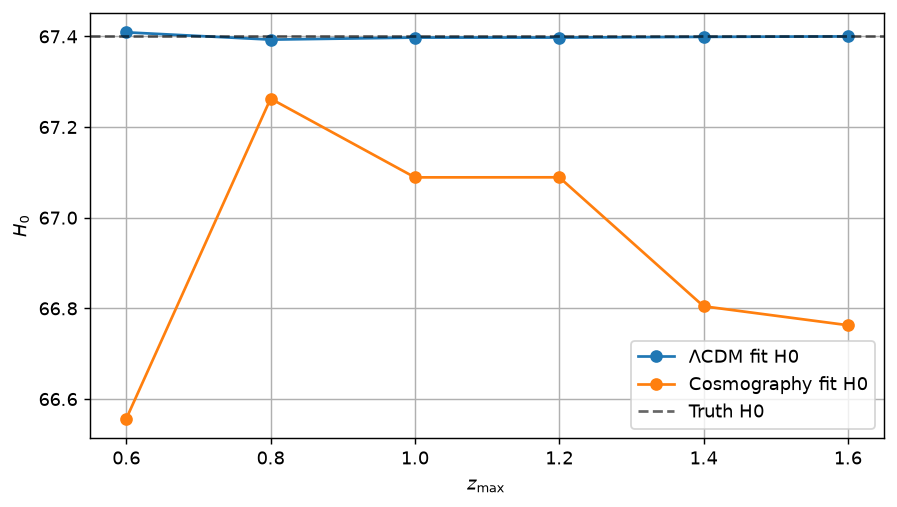

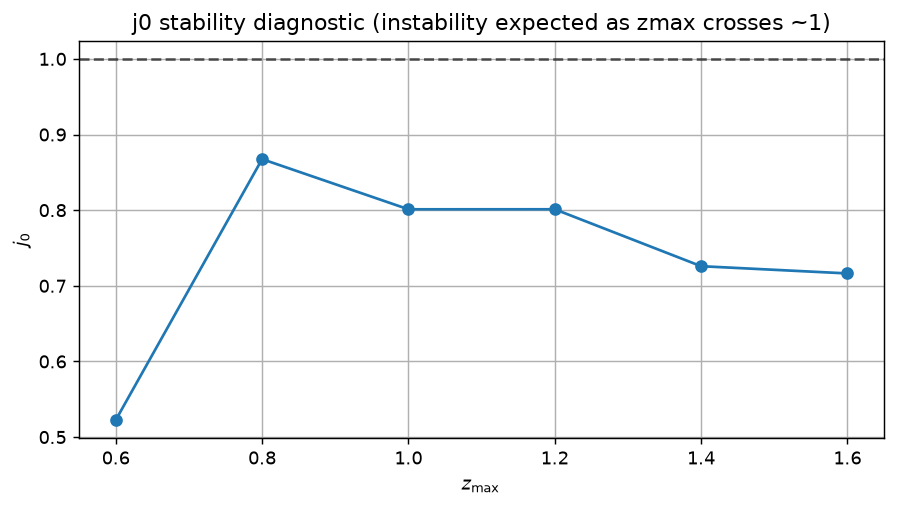

In [29]:
print("\n=== TASK 3: ΛCDM mock consistency test ===")
print(f"Truth (input):      H0 = {H0_truth:.3f},  Ωm = {Om_truth:.3f}")
print(f"ΛCDM fit (mock):    H0 = {H0_fit_lcdm:.3f},  Ωm = {Om_fit_lcdm:.3f}")
print(f"Cosmo fit (mock):   H0 = {H0_fit_cosmo:.3f},  q0 = {q0_fit_cosmo:.3f},  j0 = {j0_fit_cosmo:.3f}")
print("========================================\n")

if scan.size:
    print("zmax  H0_LCDM  Om_LCDM  H0_cosmo  q0_cosmo  j0_cosmo   N_SN  N_BAO")
    for r in scan:
        print(f"{r[0]:3.1f}  {r[1]:7.3f}  {r[2]:6.3f}  {r[3]:8.3f}  {r[4]:8.3f}  {r[5]:8.3f}  {int(r[6]):5d}  {int(r[7]):5d}")

    plt.figure(figsize=(7,4))
    plt.plot(scan[:,0], scan[:,1], "o-", label="ΛCDM fit H0")
    plt.plot(scan[:,0], scan[:,3], "o-", label="Cosmography fit H0")
    plt.axhline(H0_truth, ls="--", color="k", alpha=0.6, label="Truth H0")
    plt.xlabel(r"$z_{\max}$")
    plt.ylabel(r"$H_0$")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7,4))
    plt.plot(scan[:,0], scan[:,5], "o-")
    plt.axhline(1.0, ls="--", color="k", alpha=0.6)
    plt.xlabel(r"$z_{\max}$")
    plt.ylabel(r"$j_0$")
    plt.title("j0 stability diagnostic (instability expected as zmax crosses ~1)")
    plt.tight_layout()
    plt.show()
else:
    print("z_max scan produced no rows (insufficient SN/BAO points in the requested zmax grid).")

In [30]:
_required = [
    "zHD_all","zHEL_all","mu_sn_mock","L_sn",
    "z_bao_vec","obs_bao_vec","y_bao_mock","L_bao",
    "c_light","rs_fid","H0_truth"
]
missing = [v for v in _required if v not in globals()]
if missing:
    raise RuntimeError("Missing required variables from Task 3: " + ", ".join(missing))

def _scalar(x):
    """Force scalar float even if x is array-like."""
    return float(np.asarray(x).reshape(-1)[0])

def _chi2_from_chol(L, r):
    y = solve_triangular(L, r, lower=True, check_finite=False)
    return float(y @ y)

def _joint_chi2(mu_model, y_bao_model):
    return _chi2_from_chol(L_sn, (mu_sn_mock - mu_model)) + _chi2_from_chol(L_bao, (y_bao_mock - y_bao_model))

def _y_of_z(z):
    z = np.asarray(z)
    return z / (1.0 + z)

def _polyH(u, params):
    """
    H(u) = H0 * (1 + a1 u + a2 u^2 + ... + an u^n)
    params = [H0, a1, a2, ..., an]
    """
    H0 = params[0]
    a = np.asarray(params[1:], float)
    u = np.asarray(u, float)
    series = 1.0
    if len(a):
        for k, ak in enumerate(a, start=1):
            series = series + ak * (u**k)
    return H0 * series

def _chi_from_H(z, H_of_z, ngrid=4000):
    z = np.asarray(z)
    zmax = float(np.max(z))
    zg = np.linspace(0.0, zmax, ngrid)
    Hzg = np.asarray(H_of_z(zg), float)
    if np.any(Hzg <= 0):
        return None
    chi_grid = cumulative_trapezoid(1.0/Hzg, zg, initial=0.0)
    return np.interp(z, zg, chi_grid)

def _mu_from_chi(zHD, zHEL, chi):
    dL = (1.0 + zHEL) * c_light * chi
    return 5.0*np.log10(dL) + 25.0

def _bao_vector_from_DM_DH_DV(z_vec, obs_vec, DM, DH, DV):
    out = np.empty_like(z_vec, dtype=float)
    for i, obs in enumerate(obs_vec):
        o = str(obs)
        if "DM_over" in o:
            out[i] = DM[i] / rs_fid
        elif "DH_over" in o:
            out[i] = DH[i] / rs_fid
        elif "DV_over" in o:
            out[i] = DV[i] / rs_fid
        else:
            out[i] = DV[i] / rs_fid
    return out

def _derived_q0_j0_from_H(H_func, h=1e-4):
    """
    Robust q0 and j0 from H(z):
      q(z) = (1+z)/H * dH/dz - 1
      j(z) = q(2q+1) + (1+z) dq/dz
    """
    def Hs(z):
        return _scalar(H_func(z))

    z0 = 0.0
    Hm = Hs(z0 - h)
    H0 = Hs(z0)
    Hp = Hs(z0 + h)
    dHdz = (Hp - Hm) / (2*h)
    q0 = (1.0 + z0) * (dHdz / H0) - 1.0

    def q_of_z(z):
        Hz = Hs(z)
        Hm2 = Hs(z - h)
        Hp2 = Hs(z + h)
        dH = (Hp2 - Hm2) / (2*h)
        return (1.0 + z) * (dH / Hz) - 1.0

    dqdz = (q_of_z(z0 + h) - q_of_z(z0 - h)) / (2*h)
    j0 = q0 * (2*q0 + 1.0) + (1.0 + z0) * dqdz
    return float(q0), float(j0)

In [31]:
def _make_model(order, variable="z"):
    """
    Builds (mu_model(params), bao_model(params), H_of_z_factory(params)).
    variable: 'z' or 'y' where y=z/(1+z).
    params = [H0, a1..a_order]
    """
    def H_of_z_factory(params):
        def H_of_z(z):
            if variable == "z":
                u = np.asarray(z, float)
            else:
                u = _y_of_z(np.asarray(z, float))
            return _polyH(u, params)
        return H_of_z

    def mu_model(params):
        H_of_z = H_of_z_factory(params)
        chi = _chi_from_H(zHD_all, H_of_z)
        if chi is None:
            return None
        return _mu_from_chi(zHD_all, zHEL_all, chi)

    def bao_model(params):
        H_of_z = H_of_z_factory(params)
        chi = _chi_from_H(z_bao_vec, H_of_z)
        if chi is None:
            return None
        DM = c_light * chi
        Hz = np.asarray(H_of_z(z_bao_vec), float)
        if np.any(Hz <= 0):
            return None
        DH = c_light / Hz
        DV = (z_bao_vec * (DM**2) * DH) ** (1.0/3.0)
        return _bao_vector_from_DM_DH_DV(z_bao_vec, obs_bao_vec, DM, DH, DV)

    return mu_model, bao_model, H_of_z_factory

def fit_cosmography_poly(order, variable="z"):
    mu_model, bao_model, H_factory = _make_model(order, variable=variable)

    # initial guess near ΛCDM-ish (H0 close to truth, small coefficients)
    x0 = np.zeros(order+1)
    x0[0] = H0_truth
    x0[1] = 0.45  # approx (1+q0) with q0~ -0.55

    def obj(p):
        H0 = p[0]
        if not (40 < H0 < 90):
            return 1e99
        mu_m = mu_model(p)
        if mu_m is None:
            return 1e99
        y_m = bao_model(p)
        if y_m is None:
            return 1e99
        return _joint_chi2(mu_m, y_m)

    res = minimize(obj, x0=x0, method="Powell",
                   options={"maxiter": 1500, "xtol": 1e-6, "ftol": 1e-6, "disp": False})

    H_of_z = H_factory(res.x)
    q0, j0 = _derived_q0_j0_from_H(H_of_z)

    return {
        "variable": variable,
        "order": order,
        "success": res.success,
        "nit": res.nit,
        "chi2": res.fun,
        "H0": float(res.x[0]),
        "q0": q0,
        "j0": j0
    }

In [32]:
orders = [2, 3, 4, 5]
results = []
for n in orders:
    results.append(fit_cosmography_poly(n, variable="z"))
    results.append(fit_cosmography_poly(n, variable="y"))

In [33]:
print("\n=== Optional strengthening: order + variable sensitivity ===")
print("var  order  success  nit   chi2          H0        q0        j0")
for r in results:
    print(f"{r['variable']:>1}    {r['order']:>2d}    {str(r['success']):>5s}  {r['nit']:>4d}  {r['chi2']:>10.2f}  "
          f"{r['H0']:>8.3f}  {r['q0']:>8.3f}  {r['j0']:>8.3f}")


=== Optional strengthening: order + variable sensitivity ===
var  order  success  nit   chi2          H0        q0        j0
z     2     True     8    14916.00    66.078    -0.393     0.586
y     2     True    15  2256412.84    90.000    -3.352    28.791
z     3     True    17     2028.14    67.219    -0.506     0.931
y     3     True    53    81767.19    47.000     6.165   -22.618
z     4     True    16     2592.03    66.831    -0.454     0.687
y     4     True    27    45843.41    55.421     2.374   -14.864
z     5     True    24     1943.59    67.338    -0.518     0.958
y     5     True    47     3045.20    73.694    -1.807    14.180


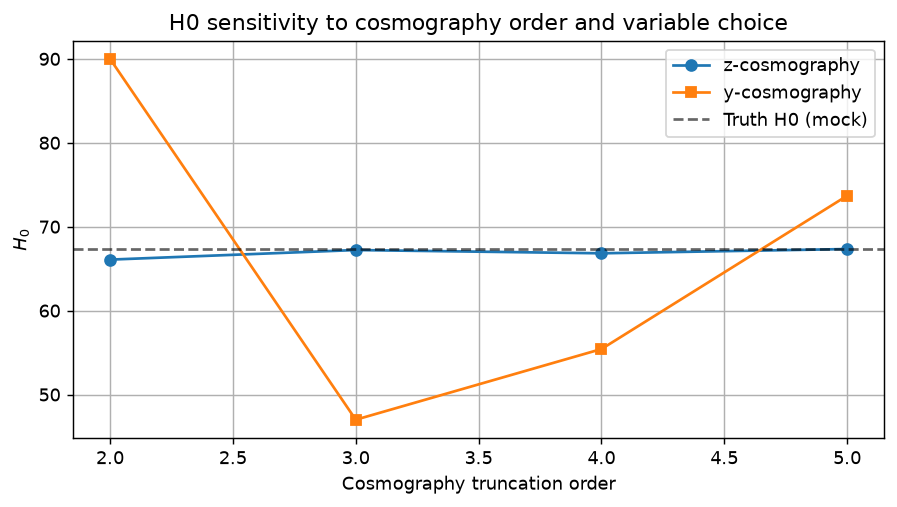

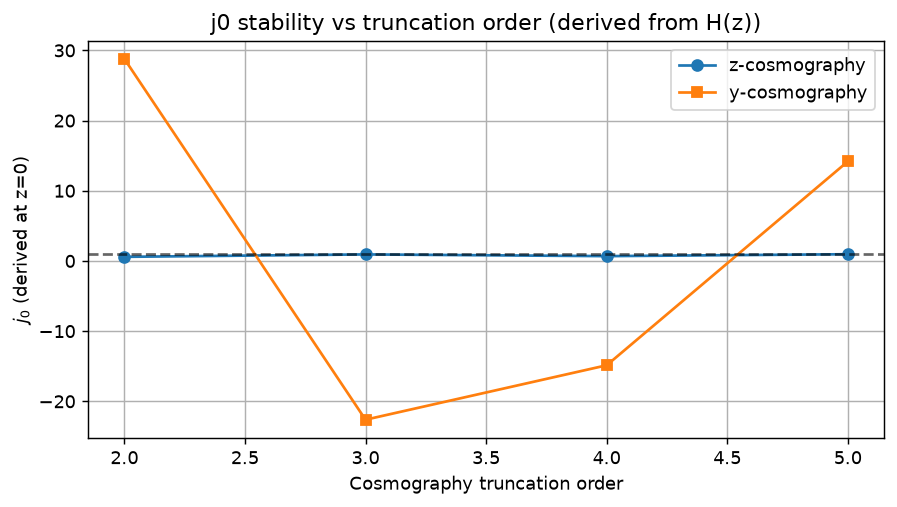

In [34]:
plt.figure(figsize=(7,4))
for var, marker in [("z","o"), ("y","s")]:
    xs = [r["order"] for r in results if r["variable"] == var]
    ys = [r["H0"]    for r in results if r["variable"] == var]
    plt.plot(xs, ys, marker+"-", label=f"{var}-cosmography")
plt.axhline(H0_truth, ls="--", color="k", alpha=0.6, label="Truth H0 (mock)")
plt.xlabel("Cosmography truncation order")
plt.ylabel(r"$H_0$")
plt.title("H0 sensitivity to cosmography order and variable choice")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,4))
for var, marker in [("z","o"), ("y","s")]:
    xs = [r["order"] for r in results if r["variable"] == var]
    ys = [r["j0"]    for r in results if r["variable"] == var]
    plt.plot(xs, ys, marker+"-", label=f"{var}-cosmography")
plt.axhline(1.0, ls="--", color="k", alpha=0.6)
plt.xlabel("Cosmography truncation order")
plt.ylabel(r"$j_0$ (derived at z=0)")
plt.title("j0 stability vs truncation order (derived from H(z))")
plt.legend()
plt.tight_layout()
plt.show()

## Highest-priority robustness analyses

The DESI BAO observables constrain distances relative to the sound horizon, so without an external calibration they constrain the product $H_0 r_d$, not $H_0$ and $r_d$ separately. The joint fits below therefore report $H_0r_d$ as the data-constrained scale and show $H_0$ only conditional on an explicitly stated $r_d$. Supernova-only fits profile out the common distance-modulus offset. The redshift-cut analysis follows the published DES-only selection ($z>0.5, 0.6, 0.7, 0.8$) and calibrates the apparent trend with mocks drawn from the released full covariance.

Real Dovekie + DESI fits (BAO constrain H0*r_d, not H0 alone):
  Flat LCDM: H0*r_d = 10087.2 km/s, Omega_m = 0.3060
    chi2_SN = 1634.045; chi2_BAO = 11.232; chi2_total = 1645.278
  CPL:       H0*r_d = 9943.4 km/s, Omega_m = 0.3142, w0 = -0.8434, wa = -0.5357
    chi2_SN = 1629.537; chi2_BAO = 8.583; chi2_total = 1638.120
H0 conditional on r_d = 147.09 Mpc: LCDM 68.578, CPL 67.601 km/s/Mpc
A +/-1% shift in assumed r_d shifts conditional H0 by the opposite +/-1%; the fit measures H0*r_d.
AIC (LCDM, CPL) = 1651.278, 1648.120; BIC (LCDM, CPL) = 1667.819, 1675.688; k = 3, 5 (includes profiled SN offset)
Model comparison (CPL minus LCDM): Delta AIC = -3.158; Delta BIC = 7.869
Nested-model likelihood-ratio statistic = 7.158 (2 dof, nominal p = 0.0279)


LCDM profile 68% (Delta chi2=1): Omega_m [0.3000, 0.3128]; H0*r_d [10033, 10144] km/s
LCDM profile 95% (Delta chi2=3.84): Omega_m [0.2950, 0.3208]; H0*r_d [9967, 10214] km/s


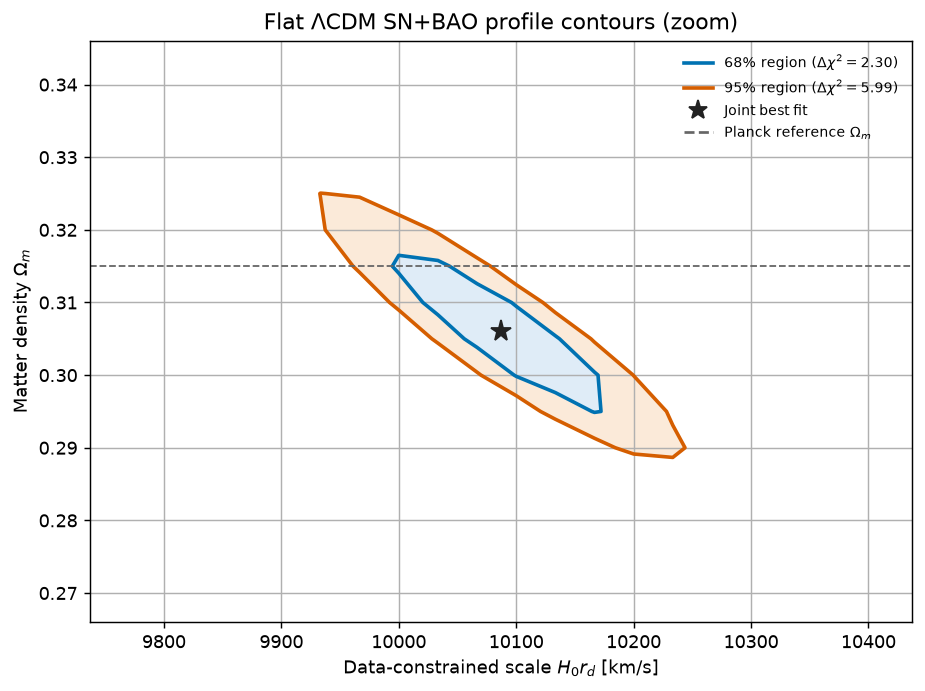

CPL local Gaussian 1-sigma (Delta chi2=1; not profile intervals): H0*r_d +/- 83, Omega_m +/- 0.0140, w0 +/- 0.070, wa +/- 0.454


CPL one-parameter profile intervals (other parameters reoptimized):
parameter confidence     lower      upper  scan_edge
   H0*r_d        68% 9901.8451 10026.7792      False
   H0*r_d        95% 9818.7562 10107.3986      False
  Omega_m        68%    0.3002     0.3268      False
  Omega_m        95%    0.2792     0.3382      False
       w0        68%   -0.8785    -0.7716      False
       w0        95%   -0.9487    -0.6991      False
       wa        68%   -0.9167    -0.0807      False
       wa        95%   -1.3333     0.3770      False


In [ ]:
from scipy.optimize import minimize
from scipy.integrate import cumulative_trapezoid
from scipy.stats import chi2 as chi2_distribution

C_LIGHT = 299792.458
P_full = np.linalg.inv(cov_masked)


def load_bao_real(mean_path, cov_path):
    rows = []
    with open(mean_path, "r") as source:
        for line in source:
            line = line.strip()
            if line and not line.startswith("#"):
                z, value, quantity = line.split()
                rows.append((float(z), float(value), quantity))
    z = np.array([row[0] for row in rows], dtype=float)
    y = np.array([row[1] for row in rows], dtype=float)
    quantities = np.array([row[2] for row in rows], dtype=str)
    covariance = np.atleast_2d(np.loadtxt(cov_path, dtype=float))
    if covariance.shape != (len(y), len(y)):
        raise ValueError("BAO covariance shape does not match the mean vector")
    return z, quantities, y, covariance


bao_z, bao_quantity, bao_y, bao_cov = load_bao_real(
    "DATA/BAO/desi_gaussian_bao_ALL_GCcomb_mean.txt",
    "DATA/BAO/desi_gaussian_bao_ALL_GCcomb_cov.txt",
)
bao_precision = np.linalg.inv(bao_cov)
bao_y_precision = bao_precision @ bao_y
bao_y_chi2 = float(bao_y @ bao_y_precision)


def expansion_e2(z, Om, w0=-1.0, wa=0.0):
    z = np.asarray(z, dtype=float)
    de = (1.0 - Om) * (1.0 + z) ** (3.0 * (1.0 + w0 + wa)) * np.exp(-3.0 * wa * z / (1.0 + z))
    return Om * (1.0 + z) ** 3 + de


def comoving_integral(z, Om, w0=-1.0, wa=0.0, n_grid=6000):
    z = np.asarray(z, dtype=float)
    zmax = float(max(1.0, np.max(z)))
    z_grid = np.linspace(0.0, zmax, n_grid)
    e2_grid = expansion_e2(z_grid, Om, w0, wa)
    if np.any(~np.isfinite(e2_grid)) or np.any(e2_grid <= 0.0):
        raise ValueError("The expansion rate is not real and positive over the integration range.")
    integral = cumulative_trapezoid(1.0 / np.sqrt(e2_grid), z_grid, initial=0.0)
    return np.interp(z, z_grid, integral)


def lcdm_mu(zHD, zHEL, H0, Om):
    integral = comoving_integral(zHD, Om)
    return 5.0 * np.log10((1.0 + np.asarray(zHEL)) * (C_LIGHT / H0) * integral) + 25.0


def cpl_mu(zHD, zHEL, H0, Om, w0, wa):
    integral = comoving_integral(zHD, Om, w0, wa)
    return 5.0 * np.log10((1.0 + np.asarray(zHEL)) * (C_LIGHT / H0) * integral) + 25.0


def bao_vector_from_integral(q_h0rd, z, quantities, integral, Om, w0=-1.0, wa=0.0):
    e = np.sqrt(expansion_e2(z, Om, w0, wa))
    dm_over_rd = (C_LIGHT / q_h0rd) * integral
    dh_over_rd = C_LIGHT / (q_h0rd * e)
    dv_over_rd = (z * dm_over_rd**2 * dh_over_rd) ** (1.0 / 3.0)
    model = np.empty(len(z), dtype=float)
    for i, quantity in enumerate(quantities):
        if quantity.startswith("DM_"):
            model[i] = dm_over_rd[i]
        elif quantity.startswith("DH_"):
            model[i] = dh_over_rd[i]
        elif quantity.startswith("DV_"):
            model[i] = dv_over_rd[i]
        else:
            raise ValueError("Unknown BAO observable: " + quantity)
    return model


def lcdm_bao_vector(q_h0rd, Om):
    integral = comoving_integral(bao_z, Om)
    return bao_vector_from_integral(q_h0rd, bao_z, bao_quantity, integral, Om)


def cpl_bao_vector(q_h0rd, Om, w0, wa):
    integral = comoving_integral(bao_z, Om, w0, wa)
    return bao_vector_from_integral(q_h0rd, bao_z, bao_quantity, integral, Om, w0, wa)


ones_full = np.ones(len(mu_all))
P1_full = P_full @ ones_full
P1_full_norm = float(ones_full @ P1_full)

def profiled_sn_chi2(model):
    residual = mu_all - model
    projected = P_full @ residual
    return float(residual @ projected - (ones_full @ projected) ** 2 / P1_full_norm)


def lcdm_joint_objective(p):
    q_h0rd, Om = 10000.0 * p[0], p[1]
    sn = profiled_sn_chi2(lcdm_mu(zHD_all, zHEL_all, 70.0, Om))
    bao_residual = bao_y - lcdm_bao_vector(q_h0rd, Om)
    return sn + float(bao_residual @ bao_precision @ bao_residual)


real_lcdm_result = minimize(
    lcdm_joint_objective,
    x0=np.array([1.0, 0.30]),
    method="L-BFGS-B",
    bounds=[(0.70, 1.30), (0.05, 0.99)],
    options={"ftol": 1e-12, "gtol": 1e-7, "maxiter": 1000, "maxls": 40},
)
if not real_lcdm_result.success:
    raise RuntimeError("LCDM joint fit did not converge: " + real_lcdm_result.message)
q_lcdm = 10000.0 * float(real_lcdm_result.x[0])
om_lcdm = float(real_lcdm_result.x[1])


def cpl_joint_objective(p):
    q_h0rd, Om, w0, wa = 10000.0 * p[0], p[1], p[2], p[3]
    e2 = expansion_e2(np.concatenate((zHD_all, bao_z)), Om, w0, wa)
    if np.any(~np.isfinite(e2)) or np.any(e2 <= 0.0):
        return 1e100
    sn = profiled_sn_chi2(cpl_mu(zHD_all, zHEL_all, 70.0, Om, w0, wa))
    bao_residual = bao_y - cpl_bao_vector(q_h0rd, Om, w0, wa)
    return sn + float(bao_residual @ bao_precision @ bao_residual)


cpl_starts = [
    np.array([real_lcdm_result.x[0], om_lcdm, -1.0, 0.0]),
    np.array([1.0, 0.30, -0.8, -0.4]),
    np.array([1.0, 0.35, -1.2, 0.5]),
]
cpl_results = [
    minimize(
        cpl_joint_objective,
        x0=start,
        method="L-BFGS-B",
        bounds=[(0.70, 1.30), (0.05, 0.99), (-2.0, 1.0), (-3.0, 2.0)],
        options={"ftol": 1e-11, "gtol": 2e-7, "maxiter": 1500, "maxls": 40},
    )
    for start in cpl_starts
]
real_cpl_result = min(cpl_results, key=lambda result: result.fun)
if not real_cpl_result.success:
    raise RuntimeError("CPL joint fit did not converge: " + real_cpl_result.message)
q_cpl = 10000.0 * float(real_cpl_result.x[0])
om_cpl, w0_cpl, wa_cpl = map(float, real_cpl_result.x[1:])

sn_chi2_lcdm = profiled_sn_chi2(lcdm_mu(zHD_all, zHEL_all, 70.0, om_lcdm))
bao_resid_lcdm = bao_y - lcdm_bao_vector(q_lcdm, om_lcdm)
bao_chi2_lcdm = float(bao_resid_lcdm @ bao_precision @ bao_resid_lcdm)
sn_chi2_cpl = profiled_sn_chi2(cpl_mu(zHD_all, zHEL_all, 70.0, om_cpl, w0_cpl, wa_cpl))
bao_resid_cpl = bao_y - cpl_bao_vector(q_cpl, om_cpl, w0_cpl, wa_cpl)
bao_chi2_cpl = float(bao_resid_cpl @ bao_precision @ bao_resid_cpl)

print("Real Dovekie + DESI fits (BAO constrain H0*r_d, not H0 alone):")
print("  Flat LCDM: H0*r_d = %.1f km/s, Omega_m = %.4f" % (q_lcdm, om_lcdm))
print("    chi2_SN = %.3f; chi2_BAO = %.3f; chi2_total = %.3f" % (sn_chi2_lcdm, bao_chi2_lcdm, real_lcdm_result.fun))
print("  CPL:       H0*r_d = %.1f km/s, Omega_m = %.4f, w0 = %.4f, wa = %.4f" % (q_cpl, om_cpl, w0_cpl, wa_cpl))
print("    chi2_SN = %.3f; chi2_BAO = %.3f; chi2_total = %.3f" % (sn_chi2_cpl, bao_chi2_cpl, real_cpl_result.fun))

rd_fiducial = 147.09
print("H0 conditional on r_d = %.2f Mpc: LCDM %.3f, CPL %.3f km/s/Mpc" % (rd_fiducial, q_lcdm / rd_fiducial, q_cpl / rd_fiducial))
print("A +/-1% shift in assumed r_d shifts conditional H0 by the opposite +/-1%; the fit measures H0*r_d.")

k_lcdm, k_cpl = 3, 5  # include the profiled SN distance-modulus offset
n_total = len(mu_all) + len(bao_y)
aic_lcdm = real_lcdm_result.fun + 2.0 * k_lcdm
aic_cpl = real_cpl_result.fun + 2.0 * k_cpl
bic_lcdm = real_lcdm_result.fun + k_lcdm * np.log(n_total)
bic_cpl = real_cpl_result.fun + k_cpl * np.log(n_total)
delta_chi2 = float(real_lcdm_result.fun - real_cpl_result.fun)
if delta_chi2 < -1e-5:
    raise RuntimeError("CPL fit is worse than its nested LCDM submodel; check optimizer convergence.")
lr_p = float(chi2_distribution.sf(max(0.0, delta_chi2), df=2))
print("AIC (LCDM, CPL) = %.3f, %.3f; BIC (LCDM, CPL) = %.3f, %.3f; k = %d, %d (includes profiled SN offset)" % (aic_lcdm, aic_cpl, bic_lcdm, bic_cpl, k_lcdm, k_cpl))
print("Model comparison (CPL minus LCDM): Delta AIC = %.3f; Delta BIC = %.3f" % (aic_cpl - aic_lcdm, bic_cpl - bic_lcdm))
print("Nested-model likelihood-ratio statistic = %.3f (2 dof, nominal p = %.4g)" % (max(0.0, delta_chi2), lr_p))


def profile_interval(grid, profile, threshold):
    best_i = int(np.argmin(profile))
    delta = profile - profile[best_i]
    left = best_i
    while left > 0 and delta[left - 1] <= threshold:
        left -= 1
    right = best_i
    while right + 1 < len(grid) and delta[right + 1] <= threshold:
        right += 1
    if left == 0:
        lower, lower_at_edge = float(grid[0]), True
    else:
        lower = float(np.interp(threshold, [delta[left - 1], delta[left]], [grid[left - 1], grid[left]]))
        lower_at_edge = False
    if right == len(grid) - 1:
        upper, upper_at_edge = float(grid[-1]), True
    else:
        upper = float(np.interp(threshold, [delta[right], delta[right + 1]], [grid[right], grid[right + 1]]))
        upper_at_edge = False
    return lower, upper, lower_at_edge or upper_at_edge


# Profile likelihood contours for the two LCDM parameters over a broad domain.
om_profile_grid = np.linspace(0.05, 0.80, 151)
q_profile_grid = np.linspace(7000.0, 13000.0, 181)
lcdm_profile_surface = np.empty((len(om_profile_grid), len(q_profile_grid)))
for i, Om in enumerate(om_profile_grid):
    sn_value = profiled_sn_chi2(lcdm_mu(zHD_all, zHEL_all, 70.0, float(Om)))
    bao_template = lcdm_bao_vector(10000.0, float(Om))
    scale = (10000.0 / q_profile_grid)[:, None]
    bao_models = scale * bao_template[None, :]
    bao_residuals = bao_y[None, :] - bao_models
    bao_values = np.einsum("bi,ij,bj->b", bao_residuals, bao_precision, bao_residuals)
    lcdm_profile_surface[i] = sn_value + bao_values
om_profile = np.min(lcdm_profile_surface, axis=1)
q_profile = np.min(lcdm_profile_surface, axis=0)
for label, threshold in [("68% (Delta chi2=1)", 1.0), ("95% (Delta chi2=3.84)", 3.84)]:
    om_lo, om_hi, om_edge = profile_interval(om_profile_grid, om_profile, threshold)
    q_lo, q_hi, q_edge = profile_interval(q_profile_grid, q_profile, threshold)
    print("LCDM profile %s: Omega_m [%.4f, %.4f]%s; H0*r_d [%.0f, %.0f]%s km/s" % (
        label, om_lo, om_hi, " (grid edge)" if om_edge else "", q_lo, q_hi, " (grid edge)" if q_edge else ""))


fig, ax = plt.subplots(figsize=(7, 5.2), constrained_layout=True)
delta_surface = lcdm_profile_surface - np.min(lcdm_profile_surface)
ax.contourf(
    q_profile_grid, om_profile_grid, delta_surface,
    levels=[0.0, 2.30, 5.99], colors=["#DCEAF7", "#FBE8D5"], alpha=0.9,
)
contours = ax.contour(
    q_profile_grid, om_profile_grid, delta_surface,
    levels=[2.30, 5.99], colors=["#0072B2", "#D55E00"], linewidths=2,
)
ax.plot(q_lcdm, om_lcdm, marker="*", ms=12, color="#222222", label="Joint best fit")
ax.axhline(0.315, color="#666666", ls="--", lw=1, label="Planck reference $\\Omega_m$")
ax.set_xlim(q_lcdm - 350.0, q_lcdm + 350.0)
ax.set_ylim(om_lcdm - 0.04, om_lcdm + 0.04)
ax.set_xlabel(r"Data-constrained scale $H_0 r_d$ [km/s]")
ax.set_ylabel(r"Matter density $\Omega_m$")
ax.set_title(r"Flat $\Lambda$CDM SN+BAO profile contours (zoom)")
from matplotlib.lines import Line2D
legend_handles = [
    Line2D([0], [0], color="#0072B2", lw=2, label=r"68% region ($\Delta\chi^2=2.30$)"),
    Line2D([0], [0], color="#D55E00", lw=2, label=r"95% region ($\Delta\chi^2=5.99$)"),
    Line2D([0], [0], marker="*", color="#222222", lw=0, ms=11, label="Joint best fit"),
    Line2D([0], [0], color="#666666", ls="--", label=r"Planck reference $\Omega_m$"),
]
ax.legend(handles=legend_handles, frameon=False, loc="best", fontsize=8)
plt.show()


def numerical_hessian(function, point, steps):
    point = np.asarray(point, dtype=float)
    hessian = np.zeros((len(point), len(point)), dtype=float)
    f0 = function(point)
    for i, hi in enumerate(steps):
        ei = np.zeros(len(point)); ei[i] = hi
        hessian[i, i] = (function(point + ei) - 2.0 * f0 + function(point - ei)) / hi**2
        for j in range(i):
            hj = steps[j]
            ej = np.zeros(len(point)); ej[j] = hj
            value = (function(point + ei + ej) - function(point + ei - ej) - function(point - ei + ej) + function(point - ei - ej)) / (4.0 * hi * hj)
            hessian[i, j] = hessian[j, i] = value
    return hessian


cpl_steps = np.array([5e-4, 5e-4, 2e-3, 2e-3])
cpl_hessian = numerical_hessian(cpl_joint_objective, real_cpl_result.x, cpl_steps)
cpl_eigenvalues = np.linalg.eigvalsh(cpl_hessian)
if np.all(cpl_eigenvalues > 0.0):
    cpl_covariance = 2.0 * np.linalg.inv(cpl_hessian)
    cpl_local_sigma = np.sqrt(np.diag(cpl_covariance))
    cpl_local_sigma[0] *= 10000.0
    print("CPL local Gaussian 1-sigma (Delta chi2=1; not profile intervals): H0*r_d +/- %.0f, Omega_m +/- %.4f, w0 +/- %.3f, wa +/- %.3f" % tuple(cpl_local_sigma))
else:
    print("CPL local Hessian is not positive definite; no local Gaussian parameter errors reported.")

# One-dimensional CPL profile intervals: fix one parameter and reoptimize the others.
cpl_parameter_names = ["H0*r_d", "Omega_m", "w0", "wa"]
cpl_parameter_bounds = [(0.70, 1.30), (0.05, 0.99), (-2.0, 1.0), (-3.0, 2.0)]
cpl_sigma_scaled = cpl_local_sigma.copy()
cpl_sigma_scaled[0] /= 10000.0
cpl_profile_rows = []
for parameter_index, parameter_name in enumerate(cpl_parameter_names):
    best_parameter = float(real_cpl_result.x[parameter_index])
    lower_bound, upper_bound = cpl_parameter_bounds[parameter_index]
    span = 6.0 * float(cpl_sigma_scaled[parameter_index])
    scan = np.linspace(max(lower_bound, best_parameter - span), min(upper_bound, best_parameter + span), 25)
    scan = np.unique(np.append(scan, best_parameter))
    free_indices = [i for i in range(4) if i != parameter_index]
    free_bounds = [cpl_parameter_bounds[i] for i in free_indices]
    profile_values = []
    for fixed_value in scan:
        start_free = real_cpl_result.x[free_indices]
        def fixed_objective(free_values):
            full_parameters = real_cpl_result.x.copy()
            full_parameters[parameter_index] = fixed_value
            full_parameters[free_indices] = free_values
            return cpl_joint_objective(full_parameters)
        profiled = minimize(
            fixed_objective,
            x0=start_free,
            method="L-BFGS-B",
            bounds=free_bounds,
            options={"ftol": 1e-10, "gtol": 1e-6, "maxiter": 1000, "maxls": 40},
        )
        if not profiled.success:
            raise RuntimeError("CPL profile fit failed for " + parameter_name + ": " + profiled.message)
        profile_values.append(float(profiled.fun))
    profile_values = np.asarray(profile_values)
    for confidence_label, threshold in [("68%", 1.0), ("95%", 3.84)]:
        lower, upper, at_scan_edge = profile_interval(scan, profile_values, threshold)
        conversion = 10000.0 if parameter_index == 0 else 1.0
        cpl_profile_rows.append({
            "parameter": parameter_name,
            "confidence": confidence_label,
            "lower": lower * conversion,
            "upper": upper * conversion,
            "scan_edge": at_scan_edge,
        })
print("CPL one-parameter profile intervals (other parameters reoptimized):")
print(pd.DataFrame(cpl_profile_rows).to_string(index=False, float_format=lambda x: f"{x:.4f}"))


## DES-only cumulative redshift-cut profile fits

This follows the cuts in Ó Colgáin, Pourojaghi & Sheikh-Jabbari, “Implications of DES 5YR SNe Dataset for $\Lambda$CDM” ([arXiv:2406.06389](https://arxiv.org/abs/2406.06389); [DOI](https://doi.org/10.1140/epjc/s10052-025-13995-4)): DES SNe only, then nested cuts $z>0.5, 0.6, 0.7, 0.8$. This notebook release contains 1,623 DES SNe, compared with 1,635 in that paper, so the numerical results are not an exact vintage replication. Each fit profiles the common magnitude offset and scans $\Omega_m$ on $[0,3]$. The mean redshift shown in the table is the arithmetic mean of each selected sample. A parametric bootstrap draws the DES vector from its released full covariance and refits every cut, preserving cross-object covariance and overlap between cuts. The one-sided slope test uses that full-pipeline calibration, not arbitrary fixed bin errors.

DES-only sample N = 1623; current-release cuts: 1623, 862, 552, 257, 130
 sample  N_SN  z_eff_mean  Omega_m  68% lower  68% upper  95% lower  95% upper  profile_edge
All DES  1623      0.5190   0.3100     0.2900     0.3258     0.2700     0.3462         False
z > 0.5   862      0.6649   0.3300     0.2900     0.3848     0.2500     0.4445         False
z > 0.6   552      0.7293   0.5000     0.4000     0.6211     0.3200     0.7748         False
z > 0.7   257      0.8243   0.6300     0.4200     0.9817     0.2800     1.5928         False
z > 0.8   130      0.8969   0.8700     0.4300     2.1207     0.2200     3.0000          True


Observed OLS slope of cumulative-cut Omega_m vs mean z = 1.4696
Full-covariance constant-LCDM bootstrap: one-sided p = 0.0590 +/- 0.0033 (Monte Carlo SE; 5000 mocks)
95th percentile of null slopes = 1.6110
  All DES  observed grid-edge fit=False; mock grid-edge fraction=0.0000
  z > 0.5  observed grid-edge fit=False; mock grid-edge fraction=0.0000
  z > 0.6  observed grid-edge fit=False; mock grid-edge fraction=0.0000
  z > 0.7  observed grid-edge fit=False; mock grid-edge fraction=0.0000
  z > 0.8  observed grid-edge fit=False; mock grid-edge fraction=0.0054


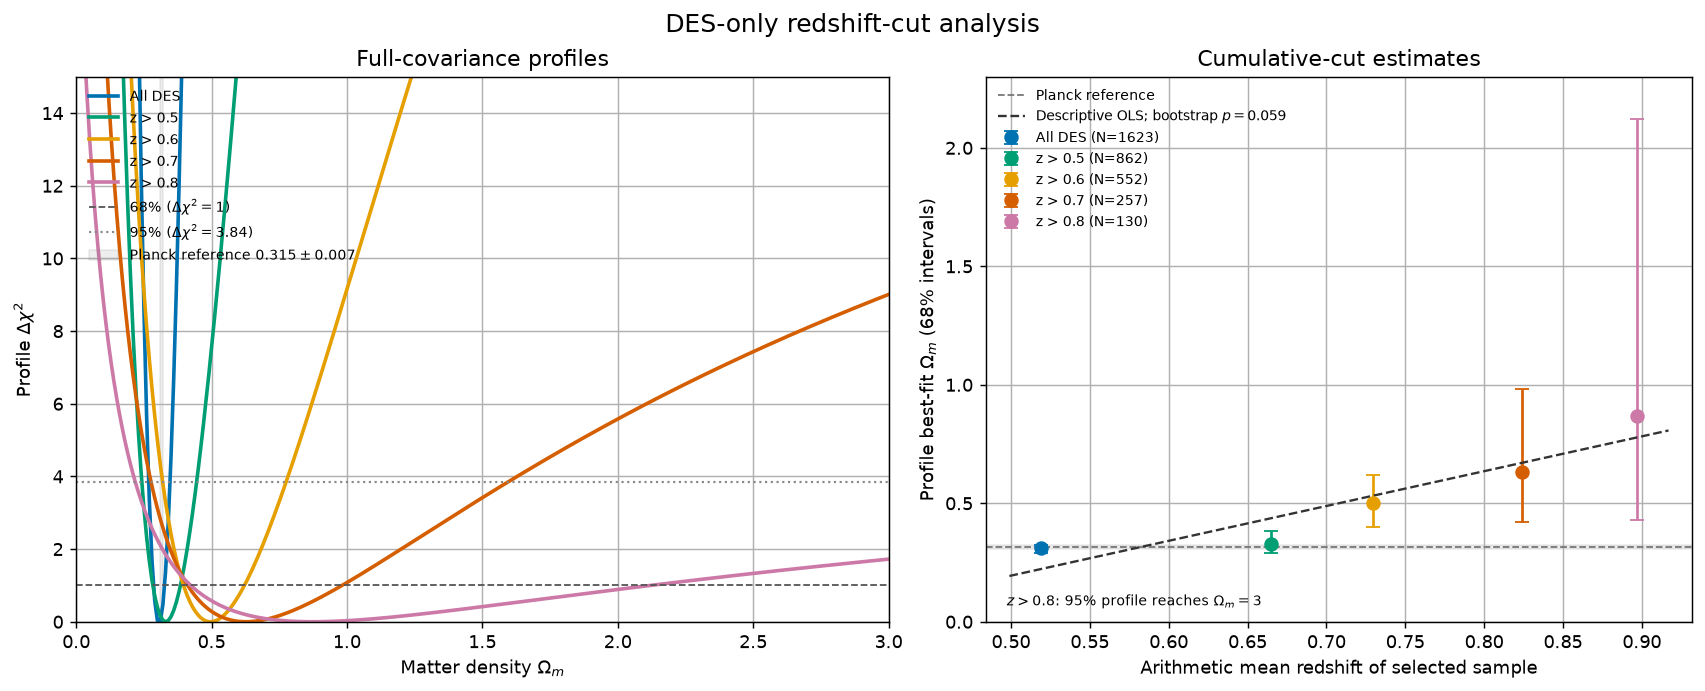

In [ ]:
from scipy.linalg import cholesky

DES_SURVEY_ID = 10
DES_MASK = df["IDSURVEY"].to_numpy() == DES_SURVEY_ID
if not np.any(DES_MASK):
    raise ValueError("No DES SNe found for IDSURVEY=10; verify the survey-code mapping.")

z_des = zHD_all[DES_MASK]
zhel_des = zHEL_all[DES_MASK]
mu_des = mu_all[DES_MASK]
cov_des = cov_masked[np.ix_(DES_MASK, DES_MASK)]
cut_labels = ["All DES", "z > 0.5", "z > 0.6", "z > 0.7", "z > 0.8"]
cut_values = [0.0, 0.5, 0.6, 0.7, 0.8]
cut_masks = [z_des > zmin for zmin in cut_values]
om_grid = np.linspace(0.0, 3.0, 301)
all_models = np.stack([lcdm_mu(z_des, zhel_des, 70.0, float(om)) for om in om_grid])

prepared_cuts = []
observed_fits = []
cut_rows = []
for label, zmin, selected in zip(cut_labels, cut_values, cut_masks):
    z = z_des[selected]
    zhel = zhel_des[selected]
    mu = mu_des[selected]
    covariance = cov_des[np.ix_(selected, selected)]
    precision = np.linalg.inv(covariance)
    one = np.ones(len(mu))
    p_one = precision @ one
    projected_precision = precision - np.outer(p_one, p_one) / float(one @ p_one)
    models = all_models[:, selected]
    reference_model = lcdm_mu(z, zhel, 70.0, float(om_grid[0]))
    # Use the same reference model for every cut so mock fits share one null cosmology.
    delta_models = models - reference_model[None, :]
    delta_models_projected = delta_models @ projected_precision
    model_quadratic = np.einsum("ij,ij->i", delta_models_projected, delta_models)
    data_delta = mu - reference_model
    scores = model_quadratic - 2.0 * (delta_models_projected @ data_delta)
    best_index = int(np.argmin(scores))
    observed_fits.append(best_index)
    prepared_cuts.append({
        "selected": selected,
        "reference_model": reference_model,
        "observed_scores": scores,
        "delta_models_projected": delta_models_projected,
        "model_quadratic": model_quadratic,
    })
    lo68, hi68, edge68 = profile_interval(om_grid, scores, 1.0)
    lo95, hi95, edge95 = profile_interval(om_grid, scores, 3.84)
    cut_rows.append({
        "sample": label,
        "N_SN": int(selected.sum()),
        "z_eff_mean": float(np.mean(z)),
        "Omega_m": float(om_grid[best_index]),
        "68% lower": lo68,
        "68% upper": hi68,
        "95% lower": lo95,
        "95% upper": hi95,
        "profile_edge": bool(edge68 or edge95),
    })

tomography = pd.DataFrame(cut_rows)
print("DES-only sample N = %d; current-release cuts: %s" % (
    int(DES_MASK.sum()), ", ".join(str(row["N_SN"]) for row in cut_rows)))
print(tomography.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

z_effective = tomography["z_eff_mean"].to_numpy()
centered_z = z_effective - z_effective.mean()
slope_denominator = float(centered_z @ centered_z)
observed_omega = tomography["Omega_m"].to_numpy()
observed_slope = float(centered_z @ observed_omega / slope_denominator)
null_omega = float(observed_omega[0])
null_model = lcdm_mu(z_des, zhel_des, 70.0, null_omega)

N_NULL = 5000
BATCH_SIZE = 100
rng = np.random.default_rng(260623)
cholesky_des = cholesky(cov_des, lower=True, check_finite=False)
mock_slopes = np.empty(N_NULL, dtype=float)
mock_fit_indices = np.empty((N_NULL, len(cut_masks)), dtype=np.int16)
for start in range(0, N_NULL, BATCH_SIZE):
    stop = min(start + BATCH_SIZE, N_NULL)
    noise = rng.standard_normal((stop - start, len(mu_des))) @ cholesky_des.T
    for cut_index, prepared in enumerate(prepared_cuts):
        selected_noise = noise[:, prepared["selected"]] + (
            null_model[prepared["selected"]] - prepared["reference_model"]
        )
        scores = prepared["model_quadratic"][None, :] - 2.0 * (
            selected_noise @ prepared["delta_models_projected"].T
        )
        mock_fit_indices[start:stop, cut_index] = np.argmin(scores, axis=1)
    mock_omega = om_grid[mock_fit_indices[start:stop]]
    mock_slopes[start:stop] = mock_omega @ centered_z / slope_denominator

p_slope = (1 + np.count_nonzero(mock_slopes >= observed_slope)) / (N_NULL + 1)
p_mc_se = float(np.sqrt(p_slope * (1.0 - p_slope) / (N_NULL + 1)))
print("Observed OLS slope of cumulative-cut Omega_m vs mean z = %.4f" % observed_slope)
print("Full-covariance constant-LCDM bootstrap: one-sided p = %.4f +/- %.4f (Monte Carlo SE; %d mocks)" % (p_slope, p_mc_se, N_NULL))
print("95th percentile of null slopes = %.4f" % float(np.quantile(mock_slopes, 0.95)))
for i, label in enumerate(cut_labels):
    edge_fraction = float(np.mean((mock_fit_indices[:, i] == 0) | (mock_fit_indices[:, i] == len(om_grid) - 1)))
    print("  %-8s observed grid-edge fit=%s; mock grid-edge fraction=%.4f" % (
        label, bool(observed_fits[i] in (0, len(om_grid) - 1)), edge_fraction))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.15, 1.0]}, constrained_layout=True)
cut_colors = ["#0072B2", "#009E73", "#E69F00", "#D55E00", "#CC79A7"]

for color, label, prepared in zip(cut_colors, cut_labels, prepared_cuts):
    delta_chi2_profile = prepared["observed_scores"] - np.min(prepared["observed_scores"])
    axes[0].plot(om_grid, delta_chi2_profile, color=color, lw=2, label=label)
axes[0].axhline(1.0, color="#555555", ls="--", lw=1, label=r"68% ($\Delta\chi^2=1$)")
axes[0].axhline(3.84, color="#888888", ls=":", lw=1.2, label=r"95% ($\Delta\chi^2=3.84$)")
axes[0].axvspan(0.308, 0.322, color="#777777", alpha=0.12, label=r"Planck reference $0.315\pm0.007$")
axes[0].set_xlim(0.0, 3.0)
axes[0].set_ylim(0.0, 15.0)
axes[0].set_xlabel(r"Matter density $\Omega_m$")
axes[0].set_ylabel(r"Profile $\Delta\chi^2$")
axes[0].set_title("Full-covariance profiles")
axes[0].legend(frameon=False, fontsize=8, loc="upper left", ncol=1)

axes[1].axhspan(0.308, 0.322, color="#777777", alpha=0.12)
axes[1].axhline(0.315, color="#777777", ls="--", lw=1, label="Planck reference")
for i, (color, label) in enumerate(zip(cut_colors, cut_labels)):
    row = tomography.iloc[i]
    yerr = [[row["Omega_m"] - row["68% lower"]], [row["68% upper"] - row["Omega_m"]]]
    axes[1].errorbar(
        row["z_eff_mean"], row["Omega_m"], yerr=yerr, fmt="o", color=color,
        capsize=4, ms=7, lw=1.5, label=f"{label} (N={int(row['N_SN'])})",
    )
fit_line = np.polyfit(z_effective, observed_omega, 1)
z_line = np.linspace(z_effective.min() - 0.02, z_effective.max() + 0.02, 100)
axes[1].plot(z_line, np.polyval(fit_line, z_line), color="#333333", ls="--", lw=1.3,
             label=fr"Descriptive OLS; bootstrap $p={p_slope:.3f}$")
axes[1].set_xlim(z_effective.min() - 0.035, z_effective.max() + 0.035)
axes[1].set_ylim(0.0, 2.3)
axes[1].set_xlabel(r"Arithmetic mean redshift of selected sample")
axes[1].set_ylabel(r"Profile best-fit $\Omega_m$ (68% intervals)")
axes[1].set_title("Cumulative-cut estimates")
axes[1].legend(frameon=False, fontsize=7.5, loc="upper left")
axes[1].text(0.03, 0.03, r"$z>0.8$: 95% profile reaches $\Omega_m=3$", transform=axes[1].transAxes, fontsize=8)
fig.suptitle("DES-only redshift-cut analysis", fontsize=14)
plt.show()

## Covariance and sample-sensitivity diagnostics

Compare full and diagonal covariance profile intervals, then show how removing the DES survey changes the constraint. The latter is a low-redshift external-only sample and is diagnostic rather than an equivalent independent-survey check. Also inspect whitened full-sample residuals and report the SN-only goodness-of-fit with its fitted-parameter count.

                              analysis    N  Omega_m   lo68   hi68   lo95   hi95  edge
              All SNe; full covariance 1820   0.3300 0.3200 0.3450 0.3100 0.3608 False
          All SNe; diagonal covariance 1820   0.3500 0.3400 0.3579 0.3300 0.3700 False
Exclude DES (external-only diagnostic)  197   0.3500 0.0300 0.7038 0.0000 1.0681  True
SN-only full-covariance goodness of fit: chi2 = 1631.421 for 1818 dof (chi2/dof = 0.8974)
Profiled common distance-modulus offset = 0.0073 mag
Whitened residual mean = 0.0450; RMS = 0.9457
 IDSURVEY    N  Mean residual (mag)  RMS residual (mag)
        5    8              -0.0092              0.1253
       10 1623               0.0517              0.2759
       63   16               0.0090              0.1398
       64   31               0.0180              0.1185
       65   22              -0.0141              0.1021
       66    3              -0.0442              0.1342
      150  117               0.0328              0.1184


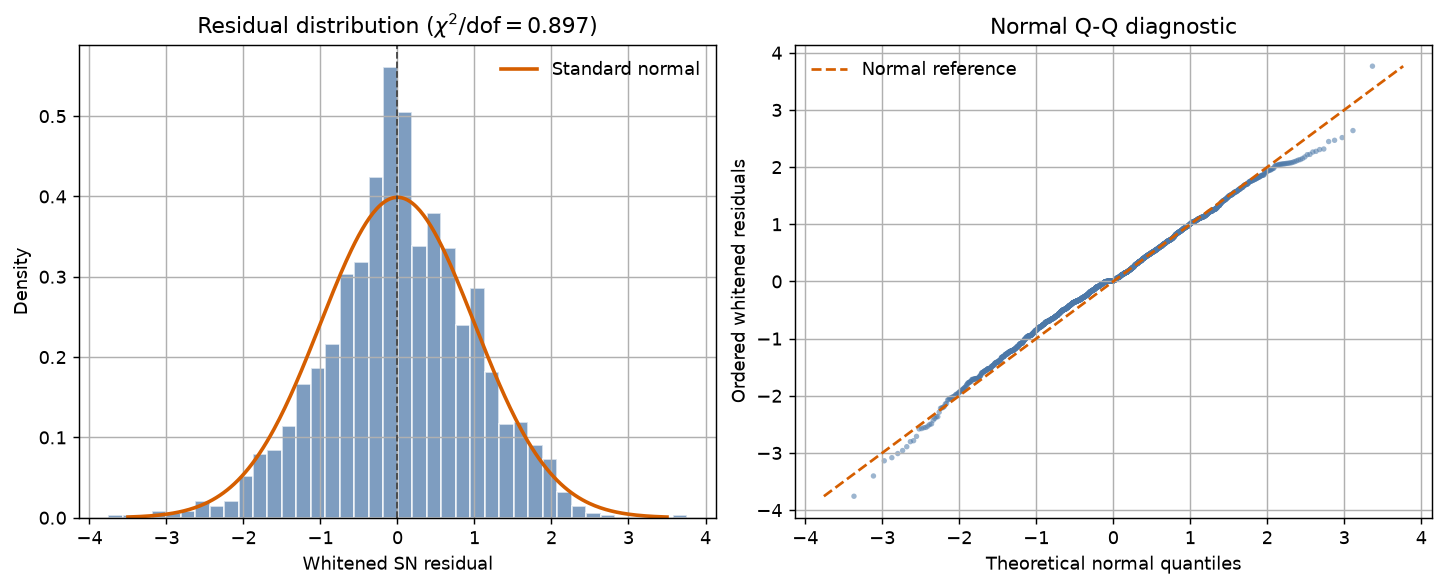

In [ ]:
from scipy.linalg import cholesky, solve_triangular

OM_DIAGNOSTIC_GRID = np.linspace(0.0, 3.0, 301)


def profile_summary(selection, covariance, precision=None):
    zhd = zHD_all[selection]
    zhel = zHEL_all[selection]
    mu = mu_all[selection]
    if precision is None:
        precision = np.linalg.inv(covariance)
    one = np.ones(len(mu))
    p_one = precision @ one
    projected_precision = precision - np.outer(p_one, p_one) / float(one @ p_one)
    models = np.stack([lcdm_mu(zhd, zhel, 70.0, float(om)) for om in OM_DIAGNOSTIC_GRID])
    model_projected = models @ projected_precision
    chi2_profile = np.einsum("ij,ij->i", model_projected, models) - 2.0 * (model_projected @ mu)
    best_index = int(np.argmin(chi2_profile))
    lo68, hi68, edge68 = profile_interval(OM_DIAGNOSTIC_GRID, chi2_profile, 1.0)
    lo95, hi95, edge95 = profile_interval(OM_DIAGNOSTIC_GRID, chi2_profile, 3.84)
    return {
        "N": len(mu),
        "Omega_m": float(OM_DIAGNOSTIC_GRID[best_index]),
        "lo68": lo68,
        "hi68": hi68,
        "lo95": lo95,
        "hi95": hi95,
        "edge": bool(edge68 or edge95),
        "chi2": float(chi2_profile[best_index]),
        "precision": precision,
        "selection": selection,
    }


all_selection = np.ones(len(mu_all), dtype=bool)
full_fit = profile_summary(all_selection, cov_masked, P_full)
diagonal_covariance = np.diag(np.diag(cov_masked))
diagonal_precision = np.diag(1.0 / np.diag(cov_masked))
diagonal_fit = profile_summary(all_selection, diagonal_covariance, diagonal_precision)
des_only_removed = df["IDSURVEY"].to_numpy() != DES_SURVEY_ID
external_covariance = cov_masked[np.ix_(des_only_removed, des_only_removed)]
external_fit = profile_summary(des_only_removed, external_covariance)

sensitivity_table = pd.DataFrame([
    {"analysis": "All SNe; full covariance", **{k: full_fit[k] for k in ("N", "Omega_m", "lo68", "hi68", "lo95", "hi95", "edge")}},
    {"analysis": "All SNe; diagonal covariance", **{k: diagonal_fit[k] for k in ("N", "Omega_m", "lo68", "hi68", "lo95", "hi95", "edge")}},
    {"analysis": "Exclude DES (external-only diagnostic)", **{k: external_fit[k] for k in ("N", "Omega_m", "lo68", "hi68", "lo95", "hi95", "edge")}},
])
print(sensitivity_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

mu_best_sn = lcdm_mu(zHD_all, zHEL_all, 70.0, full_fit["Omega_m"])
P1 = P_full @ np.ones(len(mu_all))
M_hat = float((P1 @ (mu_all - mu_best_sn)) / (P1 @ np.ones(len(mu_all))))
cholesky_full = cholesky(cov_masked, lower=True, check_finite=False)
white_residual = solve_triangular(cholesky_full, mu_all - mu_best_sn - M_hat, lower=True)
chi2_sn = float(white_residual @ white_residual)
dof_sn = len(mu_all) - 2  # profiled common offset and fitted Omega_m
print("SN-only full-covariance goodness of fit: chi2 = %.3f for %d dof (chi2/dof = %.4f)" % (chi2_sn, dof_sn, chi2_sn / dof_sn))
print("Profiled common distance-modulus offset = %.4f mag" % M_hat)
print("Whitened residual mean = %.4f; RMS = %.4f" % (float(np.mean(white_residual)), float(np.std(white_residual))))

survey_values = df["IDSURVEY"].to_numpy()
raw_residual = mu_all - mu_best_sn - M_hat
residual_rows = []
for survey in np.unique(survey_values):
    selected = survey_values == survey
    residual_rows.append((int(survey), int(selected.sum()), float(np.mean(raw_residual[selected])), float(np.std(raw_residual[selected]))))
residual_table = pd.DataFrame(residual_rows, columns=["IDSURVEY", "N", "Mean residual (mag)", "RMS residual (mag)"])
print(residual_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

from scipy.stats import norm, probplot

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
axes[0].hist(white_residual, bins=40, density=True, color="#4C78A8", alpha=0.72, edgecolor="white")
x_normal = np.linspace(-3.5, 3.5, 300)
axes[0].plot(x_normal, norm.pdf(x_normal), color="#D55E00", lw=2, label="Standard normal")
axes[0].axvline(0.0, color="#444444", ls="--", lw=1)
axes[0].set_xlabel("Whitened SN residual")
axes[0].set_ylabel("Density")
axes[0].set_title(fr"Residual distribution ($\chi^2/\mathrm{{dof}}={chi2_sn/dof_sn:.3f}$)")
axes[0].legend(frameon=False)

normal_quantiles, ordered_residuals = probplot(white_residual, dist="norm", fit=False)
axes[1].scatter(normal_quantiles, ordered_residuals, s=9, alpha=0.55, color="#4C78A8", edgecolors="none")
qq_limits = [min(float(np.min(normal_quantiles)), float(np.min(ordered_residuals))),
             max(float(np.max(normal_quantiles)), float(np.max(ordered_residuals)))]
axes[1].plot(qq_limits, qq_limits, color="#D55E00", ls="--", lw=1.5, label="Normal reference")
axes[1].set_xlabel("Theoretical normal quantiles")
axes[1].set_ylabel("Ordered whitened residuals")
axes[1].set_title("Normal Q-Q diagnostic")
axes[1].legend(frameon=False)
plt.show()

## Results and interpretation

- **Redshift dependence:** The DES-only best fits rise from $\Omega_m=0.31$ for all DES SNe to $0.87$ for $z>0.8$. However, the full-covariance constant-$\Lambda$CDM bootstrap gives a one-sided slope-test $p=0.059\pm0.003$ (Monte Carlo error; 5,000 mocks). This is suggestive but does not pass a conventional 5% threshold. The $z>0.8$ 95% profile interval reaches the scan boundary $\Omega_m=3$, so that high-redshift constraint is broad and non-Gaussian; do not summarize it as a symmetric error bar.
- **Published comparison:** The redshift cuts and DES-only selection follow arXiv:2406.06389, but the current data contain 1,623 DES SNe rather than the paper’s 1,635. The resulting cut counts and fitted values therefore differ; describe this as a method-level comparison, not a numerical replication.
- **DESI combination:** The joint fit measures $H_0r_d=10087\,\mathrm{km/s}$ and $\Omega_m=0.306$ in flat $\Lambda$CDM. $H_0=68.58\,\mathrm{km/s/Mpc}$ is conditional on the illustrative $r_d=147.09\,\mathrm{Mpc}$ calibration. CPL improves $\chi^2$ by 7.16 for two added parameters; $\Delta$AIC $=-3.16$ modestly favors CPL, while $\Delta$BIC $=+7.87$ favors $\Lambda$CDM. The nominal likelihood-ratio $p=0.028$ is not decisive on its own; present the criteria together and retain the CPL profile intervals.
- **Covariance sensitivity:** Using only the diagonal shifts the all-SN best fit from $0.33$ to $0.35$ and narrows the profile interval. The released correlations matter and should remain the primary result. Removing DES leaves only 197 external, mostly low-redshift SNe, producing a very broad interval; this is a diagnostic, not a balanced leave-one-survey-out comparison.

For the thesis, foreground the full-covariance DES-only fit and bootstrap, show the redshift-cut profile curves (especially the boundary-sensitive highest cut), and report the BAO scale as $H_0r_d$ unless an external sound-horizon calibration is explicitly adopted. The bootstrap test is specific to the stated linear slope statistic and null model; it does not establish new physics or rule out redshift-dependent systematics.